<div style="background:#0B2E59;padding:28px;border-radius:10px">
<h1 style="color:white;margin:0">Blue Bird — Krisis Ritase & Kesenjangan Armada</h1>
<h3 style="color:#F2B705;margin-top:6px">Fleet Optimization & B2B eVoucher Fraud Mitigation · Periode Oktober–Desember 2023</h3>
<p style="color:#DCE8F5">Capstone Project Module 3 — Data Analysis · Purwadhika Digital Technology School</p>
</div>

# <span style="color:#0B4F8A">Ringkasan Eksekutif</span>

**Masalah.** Ritase armada Blue Bird hanya **1.26 trip per shift**, dan hanya **0.35%** shift yang mencapai target ritase harian (≥6 trip). Rata-rata **461 menit** (≈90%) dari setiap shift habis untuk menganggur. Pada saat yang sama, **19,397 permintaan pelanggan (6.7%) gagal terlayani**, dan ada indikasi pemakaian eVoucher korporat di waktu yang tidak lazim.

**Temuan utama.**
1. **Masalahnya ada pada penempatan armada, bukan kualitas pengemudi.** Rating, masa kerja, status kepegawaian, dan tipe kendaraan tidak berpengaruh pada ritase (|ρ| < 0,01). Yang membedakan adalah **zona kerja dan pool asal**: Pool Bandara Soetta, pool terbesar (644 pengemudi), punya ritase terendah (0.97) dan 40% shift-nya berakhir tanpa satu trip pun.
2. **Supply dan demand tidak sinkron menurut jam.** Pengemudi paling banyak aktif pukul 09–11 (≈2,285 unit, hanya 8 permintaan/100 unit/jam), padahal demand memuncak pukul 13–16. Pukul 17.00 hanya ≈169 unit aktif karena **jeda pergantian shift** (shift pagi mulai 05–08, shift malam mulai 18–22).
3. **Permintaan tak terpenuhi terkonsentrasi di CBD pada jam sibuk**: tingkat pemenuhan CBD pukul 07–08 & 17–18 hanya **63%** vs 96% di jam/zona lain — 39% dari seluruh permintaan gagal terjadi di 4 jam × 1 zona ini.
4. **eVoucher korporat**: di zona non-bandara, porsi eVoucher turun drastis saat akhir pekan/malam (pola perjalanan dinas yang wajar). Namun di **Bandara**, porsinya justru naik menjadi **55%** (vs 16% pada hari kerja siang). Terdapat **≈5,931 trip eVoucher "berlebih"** senilai **Rp891 juta** dalam 3 bulan, tersebar merata di 281 klien → ini **celah kebijakan**, bukan ulah segelintir klien.

**Dampak bisnis (estimasi tahunan).** Pemulihan demand yang hilang + peningkatan ritase pool lemah + pengendalian eVoucher berpotensi menyelamatkan/menambah **≈Rp5.8 miliar per tahun** (lihat bagian Business Impact).


# <span style="color:#0B4F8A">Daftar Isi</span>
1. [Business Understanding](#bu) — latar belakang, stakeholder, problem statement, business questions
2. [Data Understanding](#du) — struktur 6 tabel, relasi (ERD), statistik deskriptif
3. [Data Cleaning](#dc) — missing values, duplikat, tipe data, standardisasi kategori, anomali argometer, outlier, konsistensi antar tabel
4. [Feature Engineering & Data Merging](#fe)
5. [Data Analysis](#da)
   - 5.1 Fleet Optimization — ritase & idle antar pool (BQ1–BQ3)
   - 5.2 Unmet Demand — kapan & di mana permintaan gagal terlayani (BQ4–BQ5)
   - 5.3 Dampak kualitas data terhadap keandalan analisis (BQ6)
   - 5.4 B2B eVoucher — pola pemakaian di waktu tidak lazim (BQ7–BQ8)
6. [Business Impact](#bi)
7. [Kesimpulan & Rekomendasi](#cr)


<a id="bu"></a>
# <span style="color:#0B4F8A">1. Business Understanding</span>

## <span style="color:#0B4F8A">1.1 Latar Belakang</span>
Blue Bird adalah pionir taksi konvensional di Indonesia yang mengandalkan **armada fisik dan puluhan ribu pengemudi tetap**. Pendapatan utama berasal dari **tarif argometer** perjalanan (reguler & charter) yang dibayar tunai, kartu kredit, aplikasi MyBluebird, maupun **eVoucher korporat** (produk B2B *Corporate Solution*).

Karena armada adalah aset tetap, **setiap jam mobil menganggur adalah biaya yang tidak tertutup pendapatan**. Setelah armada reguler menyusut akibat kompetisi ride-hailing (titik terendah 2021), strategi manajemen bergeser dari *menambah armada* menjadi **memaksimalkan utilisasi armada yang ada** — pada semester I 2024 Blue Bird melaporkan pertumbuhan pendapatan dua digit yang dikaitkan dengan peningkatan utilitas armada.

Di sisi B2B, tim Finance beberapa klien korporat mengeluhkan **transparansi pemakaian eVoucher**. Selain itu, ada masalah rekonsiliasi data antara sistem aplikasi dan sistem dispatch lama yang menimbulkan inkonsistensi pencatatan argometer dan kategori layanan.


## <span style="color:#0B4F8A">1.2 Stakeholder</span>
| Stakeholder | Kepentingan terhadap analisis |
|---|---|
| **Direktur Operasional / Fleet Management** (pengguna utama) | Kebijakan alokasi armada antar pool, jadwal shift, strategi dispatch |
| **Kepala Pool / Garasi** | Target ritase pengemudi, penempatan zona kerja harian |
| **Tim Dispatch & Call Center** | Pemenuhan permintaan pada jam & zona rawan |
| **Tim Corporate Solution (B2B Sales) & Finance** | Kebijakan approval eVoucher, laporan transparansi ke klien |
| **Tim Data Engineering** | Perbaikan kualitas data argometer & standardisasi kategori layanan |


## <span style="color:#0B4F8A">1.3 Problem Statement</span>
> **Produktivitas armada (ritase) rendah dan diduga terkait pola idle time pengemudi, permintaan pelanggan tidak selalu terpenuhi pada waktu/lokasi tertentu, dan terdapat indikasi lemahnya kontrol pemakaian eVoucher korporat.** Manajemen membutuhkan pemetaan berbasis data — baseline, besaran gap, dan target perbaikan — sebelum menetapkan kebijakan dispatch dan kebijakan approval eVoucher.

**Goal:**
1. **Fleet Optimization** — memahami pola ritase & idle antar pool untuk memperbaiki penempatan/dispatch pengemudi.
2. **B2B Fraud Mitigation** — memahami pola pemakaian eVoucher untuk memperkuat kontrol dan transparansi ke klien.

**Metrik utama:** ritase (trip/shift), % target ritase tercapai (≥6 trip), idle minutes per shift, utilisasi waktu shift, *fulfillment rate* permintaan, porsi eVoucher di waktu tidak lazim.


## <span style="color:#0B4F8A">1.4 Business Questions</span>
| # | Pertanyaan | Tujuan |
|---|---|---|
| BQ1 | Bagaimana ritase dan idle time bervariasi antar pool? Seberapa besar gap-nya? | Fleet |
| BQ2 | Faktor apa yang menjelaskan variasi ritase — karakteristik pool/zona atau karakteristik pengemudi? | Fleet |
| BQ3 | Apakah jumlah armada aktif per jam sesuai dengan pola permintaan? | Fleet |
| BQ4 | Pada jam & zona mana permintaan paling sering tidak terpenuhi? | Fleet |
| BQ5 | Berapa potensi pendapatan yang hilang akibat permintaan tak terpenuhi? | Fleet |
| BQ6 | Bagaimana kualitas data argometer memengaruhi keandalan analisis, dan bagaimana menanganinya? | Data |
| BQ7 | Apakah pola waktu & lokasi pemakaian eVoucher berbeda dari metode bayar lain? Di mana anomalinya? | B2B |
| BQ8 | Apakah anomali eVoucher terkonsentrasi pada klien/industri/pengemudi tertentu? Berapa nilainya? | B2B |


<a id="du"></a>
# <span style="color:#0B4F8A">2. Data Understanding</span>

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import json, warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Palet konsisten untuk seluruh notebook (biru Blue Bird + aksen)
NAVY, BLUE, SKY, AMBER, RED, GREY = '#0B2E59', '#1F6FB2', '#A9CBEB', '#F2B705', '#D64545', '#8C99A6'
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'axes.titleweight':'bold','axes.titlesize':13,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})

DATA_DIR = './'   # letakkan 6 file CSV di folder yang sama dengan notebook
RES = {}          # menampung angka kunci untuk slide presentasi

In [2]:
pools    = pd.read_csv(DATA_DIR+'bb_pools.csv')
corp     = pd.read_csv(DATA_DIR+'bb_corporate_clients.csv')
drivers  = pd.read_csv(DATA_DIR+'bb_drivers.csv')
shifts   = pd.read_csv(DATA_DIR+'bb_driver_shifts.csv')
requests = pd.read_csv(DATA_DIR+'bb_service_requests.csv')
trips    = pd.read_csv(DATA_DIR+'bb_trips.csv')

tables = {'bb_pools':pools,'bb_corporate_clients':corp,'bb_drivers':drivers,
          'bb_driver_shifts':shifts,'bb_service_requests':requests,'bb_trips':trips}
overview = pd.DataFrame({
    'jenis':['Dimensi','Dimensi','Dimensi','Satelit','Satelit','Fakta'],
    'grain (1 baris =)':['1 garasi/pool','1 klien korporat','1 pengemudi','1 shift kerja pengemudi','1 permintaan taksi','1 perjalanan argometer'],
    'baris':[len(t) for t in tables.values()],
    'kolom':[t.shape[1] for t in tables.values()]}, index=tables.keys())
overview

,jenis,grain (1 baris =),baris,kolom
bb_pools,Dimensi,1 garasi/pool,8,6
bb_corporate_clients,Dimensi,1 klien korporat,286,3
bb_drivers,Dimensi,1 pengemudi,4055,6
bb_driver_shifts,Satelit,1 shift kerja pengemudi,252524,9
bb_service_requests,Satelit,1 permintaan taksi,289622,7
bb_trips,Fakta,1 perjalanan argometer,318098,14


**Relasi antar tabel (ERD):** `bb_pools` 1→N `bb_drivers` 1→N `bb_driver_shifts` 1→N `bb_trips`; `bb_corporate_clients` 1→N `bb_trips` (opsional, hanya eVoucher); `bb_trips` 1→0..1 `bb_service_requests` (via `matched_trip_id`, hanya untuk permintaan yang terpenuhi).

![ERD](BlueBird_ERD.png)

In [3]:
for name, df in tables.items():
    print(f'\n=== {name} {df.shape}'); display(df.head(3))


=== bb_pools (8, 6)


,pool_id,pool_name,region_area,distance_to_soetta_km,distance_to_cbd_km,primary_zone_affinity
0,PL-CGK,Pool Bandara Soetta,Tangerang,3.50,28.00,Airport-heavy
1,PL-BSD,Pool BSD,Tangerang Selatan,32.00,26.00,Mixed
2,PL-CPT,Pool Ciputat,Tangerang Selatan,35.00,18.00,Mixed



=== bb_corporate_clients (286, 3)


,company_id,company_name,industry
0,CORP-FMC-001,PT. Nusantara FMCG 31 Tbk,FMCG
1,CORP-BNK-001,PT. Global Banking 62 Tbk,Banking
2,CORP-BNK-002,PT. Global Banking 104 Tbk,Banking



=== bb_drivers (4055, 6)


,driver_id,pool_id,driver_rating,join_date,employment_status,vehicle_type_assigned
0,DRV-CGK-17-0001,PL-CGK,4.79,2017-07-27,Tetap,Reguler
1,DRV-CGK-21-0001,PL-CGK,4.76,2021-10-13,Tetap,Reguler
2,DRV-CGK-21-0002,PL-CGK,4.54,2021-08-07,Tetap,Reguler


... (2 outputs left out)


=== bb_service_requests (289622, 7)


,request_id,requested_time,pickup_zone_type,request_source,status,matched_trip_id,wait_time_minutes
0,REQ-231001-00001,2023-10-01 05:12:14,Residential,App,Fulfilled,TRP-231001-0001,6.80
1,REQ-231001-00002,2023-10-01 05:16:53,CBD,App,Fulfilled,TRP-231001-0002,5.60
2,REQ-231001-00003,2023-10-01 05:18:35,CBD,App,Fulfilled,TRP-231001-0003,6.60



=== bb_trips (318098, 14)


,trip_id,driver_id,shift_id,company_id,trip_type,service_type,pickup_zone_type,booking_channel,booking_time,meter_start_time,dropoff_time,distance_km,payment_method,total_fare
0,TRP-231001-0001,DRV-KLG-21-0041,SFT-KLG-2310-240939,NaN,Reguler,Bluebird,Residential,App,2023-10-01 05:12:14,2023-10-01 05:18:59,2023-10-01 05:37:21,7.00,MyBluebird App,"46,500.00"
1,TRP-231001-0002,DRV-KLG-23-0004,SFT-KLG-2310-222052,NaN,Reguler,Bluebird,CBD,App,2023-10-01 05:16:53,2023-10-01 05:22:28,2023-10-01 05:35:09,2.90,MyBluebird App,"26,500.00"
2,TRP-231001-0003,DRV-HLM-18-0022,SFT-HLM-2310-152040,NaN,Reguler,Bluebird,CBD,App,2023-10-01 05:18:35,2023-10-01 05:25:14,2023-10-01 05:42:43,3.40,MyBluebird App,"29,000.00"


In [4]:
# Tipe data & ringkasan unik per kolom
info = []
for name, df in tables.items():
    for c in df.columns:
        info.append([name, c, str(df[c].dtype), df[c].isna().sum(), round(df[c].isna().mean()*100,2), df[c].nunique(), list(df[c].dropna().unique()[:4])])
pd.DataFrame(info, columns=['tabel','kolom','dtype','null','null_%','n_unique','contoh'])

,tabel,kolom,dtype,null,null_%,n_unique,contoh
0,bb_pools,pool_id,str,0,0.00,8,"[PL-CGK, PL-BSD, PL-CPT, PL-KJT]"
1,bb_pools,pool_name,str,0,0.00,8,"[Pool Bandara Soetta, Pool BSD, Pool Ciputat, ..."
2,bb_pools,region_area,str,0,0.00,6,"[Tangerang, Tangerang Selatan, Jakarta Timur, ..."
3,bb_pools,distance_to_soetta_km,float64,0,0.00,8,"[3.5, 32.0, 35.0, 38.0]"
4,bb_pools,distance_to_cbd_km,float64,0,0.00,8,"[28.0, 26.0, 18.0, 14.0]"
5,bb_pools,primary_zone_affinity,str,0,0.00,3,"[Airport-heavy, Mixed, CBD-heavy]"
6,bb_corporate_clients,company_id,str,0,0.00,286,"[CORP-FMC-001, CORP-BNK-001, CORP-BNK-002, COR..."
7,bb_corporate_clients,company_name,str,0,0.00,286,"[PT. Nusantara FMCG 31 Tbk, PT. Global Banking..."
8,bb_corporate_clients,industry,str,0,0.00,6,"[FMCG, Banking, Media, Tech StartUp]"
9,bb_drivers,driver_id,str,0,0.00,4055,"[DRV-CGK-17-0001, DRV-CGK-21-0001, DRV-CGK-21-..."


### <span style="color:#0B4F8A">Statistik deskriptif awal (data mentah)</span>

In [5]:
display(trips[['distance_km','total_fare']].describe(percentiles=[.01,.25,.5,.75,.99]).T)
display(shifts[['trip_count','total_idle_minutes']].describe().T)
display(requests[['wait_time_minutes']].describe().T)
display(drivers[['driver_rating']].describe().T)

,count,mean,std,min,1%,25%,50%,75%,99%,max
distance_km,"318,098.00",16.04,80.91,-12.00,2.50,6.10,8.60,13.10,167.20,"2,999.20"
total_fare,"318,098.00","83,241.76","123,018.34","14,000.00","24,500.00","45,000.00","60,500.00","86,500.00","690,500.00","2,503,500.00"


,count,mean,std,min,25%,50%,75%,max
trip_count,"252,524.00",1.26,1.19,0.00,0.00,1.00,2.00,10.00
total_idle_minutes,"252,524.00",460.74,71.80,0.00,422.30,467.90,508.50,660.00


,count,mean,std,min,25%,50%,75%,max
wait_time_minutes,"270,225.00",4.91,2.06,0.50,3.60,4.90,6.30,14.20


,count,mean,std,min,25%,50%,75%,max
driver_rating,"4,055.00",4.74,0.17,4.04,4.63,4.75,4.87,5.00


**Observasi awal:**
- `distance_km` memiliki nilai **negatif (min −12 km)** dan **ekstrem (maks 2.999 km)** — tidak mungkin untuk taksi dalam kota → indikasi error sensor.
- `total_fare` maks Rp2,5 juta — perlu dicek apakah perjalanan **Charter** (memang jauh) sebelum dianggap outlier.
- `trip_count` rata-rata hanya ~1,3 trip/shift dengan idle ~461 menit — sinyal awal krisis ritase.
- `service_type` punya puluhan variasi penulisan (dicek di Data Cleaning).


In [6]:
for c in ['service_type','trip_type','booking_channel','payment_method','pickup_zone_type']:
    print(f'\n{c}:'); print(trips[c].value_counts().to_string())
print('\nstatus request:'); print(requests.status.value_counts().to_string())


service_type:
service_type
Bluebird       135005
Silverbird      44857
blue bird       24047
E-Cabbie        21908
BB Reguler      16641
Goldenbird      15525
silver           8736
Reguler          7487
bb reguler       7420
BLUEBIRD         7383
SilverBird       5379
Silver Bird      3313
SILVERBIRD       3304
goldenbird       2928
Ecabbie          2671
E-cabbie         2549
Golden Bird      1914
e cabbie         1618
Listrik          1586
electric         1582
GoldenBird       1149
golden           1096

trip_type:
trip_type
Reguler    314554
Charter      3544

booking_channel:
booking_channel
App            190841
Call Center     79384
Street Hail     47873

payment_method:
payment_method
MyBluebird App        125252
Cash                   89623
eVoucher Corporate     57358
Credit Card            45865

pickup_zone_type:
pickup_zone_type
CBD            119131
Mall            57095
Residential     53939
Other           45758
Airport         42175

status request:
status
Fulfilled   

<a id="dc"></a>
# <span style="color:#0B4F8A">3. Data Cleaning</span>

Tahapan cleaning beserta alasannya:

| # | Tahap | Alasan |
|---|---|---|
| 1 | Konversi tipe data datetime & boolean | Kolom waktu terbaca sebagai teks; dibutuhkan untuk menghitung durasi, jam, hari |
| 2 | Cek duplikat (baris & primary key) | Duplikat menggandakan trip/pendapatan |
| 3 | Missing values — validasi terhadap alur bisnis | Brief: kekosongan `company_id` wajar untuk non-eVoucher; dicek konsistensinya, bukan diisi paksa |
| 4 | Standardisasi `service_type` | 22 variasi penulisan dari 2 sistem input → 4 kategori resmi |
| 5 | Anomali waktu argometer | Argo menyala sebelum booking, trip di luar jam shift |
| 6 | Anomali jarak argometer + outlier | Jarak negatif/ekstrem = error sensor; dibedakan dari Charter yang memang jauh |
| 7 | Konsistensi antar tabel | Relasi trip–shift–driver–request harus valid sebelum di-join |


## <span style="color:#0B4F8A">3.1 Tipe data</span>

In [7]:
for c in ['booking_time','meter_start_time','dropoff_time']:
    trips[c] = pd.to_datetime(trips[c])
shifts['shift_date']     = pd.to_datetime(shifts['shift_date'])
shifts['clock_in_time']  = pd.to_datetime(shifts['clock_in_time'])
shifts['clock_out_time'] = pd.to_datetime(shifts['clock_out_time'])
shifts['ritase_target_met'] = shifts['ritase_target_met'].astype(str).str.lower().eq('true')
requests['requested_time'] = pd.to_datetime(requests['requested_time'])
drivers['join_date'] = pd.to_datetime(drivers['join_date'])
print(trips.dtypes[['booking_time','meter_start_time','dropoff_time']])
print('Periode trip   :', trips.meter_start_time.min(), '→', trips.meter_start_time.max())
print('Periode shift  :', shifts.shift_date.min().date(), '→', shifts.shift_date.max().date())
print('Periode request:', requests.requested_time.min(), '→', requests.requested_time.max())

booking_time        datetime64[us]
meter_start_time    datetime64[us]
dropoff_time        datetime64[us]
dtype: object
Periode trip   : 2023-10-01 05:18:59 → 2023-12-30 08:20:25
Periode shift  : 2023-10-01 → 2023-12-29
Periode request: 2023-10-01 05:12:14 → 2023-12-30 08:20:27


Data mencakup **1 Oktober – 29 Desember 2023 (90 hari shift)**. Data request/trip tanggal 30 Desember hanya sampai ±08.20 (lanjutan shift malam 29 Des), sehingga untuk metrik *per hari* digunakan pembagi 90 hari.

In [8]:
N_DAYS = shifts.shift_date.nunique()
print('Jumlah hari operasional:', N_DAYS)

Jumlah hari operasional: 90


## <span style="color:#0B4F8A">3.2 Duplikat</span>

In [9]:
pk = {'bb_pools':'pool_id','bb_corporate_clients':'company_id','bb_drivers':'driver_id',
      'bb_driver_shifts':'shift_id','bb_service_requests':'request_id','bb_trips':'trip_id'}
pd.DataFrame({n:{'duplikat_baris':tables[n].duplicated().sum(),'duplikat_PK':tables[n][pk[n]].duplicated().sum()} for n in tables}).T

,duplikat_baris,duplikat_PK
bb_pools,0,0
bb_corporate_clients,0,0
bb_drivers,0,0
bb_driver_shifts,0,0
bb_service_requests,0,0
bb_trips,0,0


**Hasil:** tidak ada duplikat baris maupun primary key → tidak ada baris yang perlu dibuang.

## <span style="color:#0B4F8A">3.3 Missing values — validasi terhadap alur bisnis</span>

In [10]:
print('Missing trips   :', trips.isna().sum()[trips.isna().sum()>0].to_dict())
print('Missing requests:', requests.isna().sum()[requests.isna().sum()>0].to_dict())
print('\ncompany_id terisi vs payment_method:')
display(pd.crosstab(trips.payment_method, trips.company_id.notna(), margins=True).rename(columns={False:'company_id kosong',True:'company_id terisi'}))
print('matched_trip_id / wait_time kosong vs status:')
display(pd.crosstab(requests.status, requests.matched_trip_id.isna()).rename(columns={False:'terisi',True:'kosong'}))

Missing trips   : {'company_id': 260740}
Missing requests: {'matched_trip_id': 19397, 'wait_time_minutes': 19397}

company_id terisi vs payment_method:


company_id,company_id kosong,company_id terisi,All
payment_method,,,
Cash,89623,0,89623
Credit Card,45865,0,45865
MyBluebird App,125252,0,125252
eVoucher Corporate,0,57358,57358
All,260740,57358,318098


matched_trip_id / wait_time kosong vs status:


matched_trip_id,terisi,kosong
status,,
Cancelled-No Driver,0,13494
Cancelled-Timeout,0,5903
Fulfilled,270225,0


**Hasil & keputusan:**
- `company_id` kosong **100% hanya pada pembayaran non-eVoucher**, dan **100% terisi pada eVoucher** → kekosongan sesuai alur bisnis, **tidak diisi**.
- `matched_trip_id` & `wait_time_minutes` kosong **hanya pada status Cancelled** → wajar (tidak ada trip). **Tidak diisi**; pada analisis waktu tunggu hanya permintaan Fulfilled yang dipakai.


## <span style="color:#0B4F8A">3.4 Standardisasi kategori layanan (service_type)</span>

In [11]:
print('Jumlah variasi service_type mentah:', trips.service_type.nunique())
svc_map = {'bluebird':'Bluebird','blue bird':'Bluebird','bb reguler':'Bluebird','reguler':'Bluebird',
           'silverbird':'Silverbird','silver bird':'Silverbird','silver':'Silverbird',
           'goldenbird':'Goldenbird','golden bird':'Goldenbird','golden':'Goldenbird',
           'e-cabbie':'E-Cabbie','ecabbie':'E-Cabbie','e cabbie':'E-Cabbie','listrik':'E-Cabbie','electric':'E-Cabbie'}
trips['service_type_raw'] = trips['service_type']
trips['service_type'] = trips['service_type_raw'].str.strip().str.lower().map(svc_map)
print('Tidak terpetakan:', trips.service_type.isna().sum())
display(trips.groupby(['service_type','service_type_raw']).size().rename('n').reset_index().pivot_table(index='service_type_raw',columns='service_type',values='n').fillna(0).astype(int))

Jumlah variasi service_type mentah: 22
Tidak terpetakan: 0


service_type,Bluebird,E-Cabbie,Goldenbird,Silverbird
service_type_raw,,,,
BB Reguler,16641,0,0,0
BLUEBIRD,7383,0,0,0
Bluebird,135005,0,0,0
E-Cabbie,0,21908,0,0
E-cabbie,0,2549,0,0
Ecabbie,0,2671,0,0
Golden Bird,0,0,1914,0
GoldenBird,0,0,1149,0
Goldenbird,0,0,15525,0


In [12]:
# Validasi silang: kategori hasil standardisasi vs tipe armada yang ditugaskan ke pengemudi
chk = trips[['driver_id','service_type']].merge(drivers[['driver_id','vehicle_type_assigned']], on='driver_id')
pd.crosstab(chk.vehicle_type_assigned, chk.service_type)

service_type,Bluebird,E-Cabbie,Goldenbird,Silverbird
vehicle_type_assigned,,,,
Electric,0,31914,0,0
Golden,0,0,22612,0
Reguler,197983,0,0,0
Silver,0,0,0,65589


**Hasil:** 22 variasi penulisan dipetakan ke **4 kategori resmi** (Bluebird, Silverbird, Goldenbird, E-Cabbie). Validasi silang terhadap `vehicle_type_assigned` pengemudi **100% konsisten** (diagonal sempurna) → pemetaan benar.

## <span style="color:#0B4F8A">3.5 Anomali waktu argometer</span>

In [13]:
trips['trip_duration_min'] = (trips.dropoff_time - trips.meter_start_time).dt.total_seconds()/60
trips['pickup_wait_min']   = (trips.meter_start_time - trips.booking_time).dt.total_seconds()/60
print('Durasi trip ≤ 0             :', (trips.trip_duration_min<=0).sum())
neg_wait = trips.pickup_wait_min<0
print('Argo menyala SEBELUM booking:', neg_wait.sum(), f'({neg_wait.mean()*100:.2f}%)')
display(trips.loc[neg_wait,['trip_id','booking_channel','booking_time','meter_start_time','pickup_wait_min']].head())
print(trips.loc[neg_wait,'booking_channel'].value_counts(normalize=True).round(3).to_dict())

Durasi trip ≤ 0             : 0
Argo menyala SEBELUM booking: 6595 (2.07%)


,trip_id,booking_channel,booking_time,meter_start_time,pickup_wait_min
5,TRP-231001-0006,App,2023-10-01 05:33:09,2023-10-01 05:29:15,-3.90
41,TRP-231001-0042,Call Center,2023-10-01 06:19:31,2023-10-01 06:15:53,-3.63
55,TRP-231001-0056,App,2023-10-01 06:30:15,2023-10-01 06:28:23,-1.87
135,TRP-231001-0136,App,2023-10-01 07:21:41,2023-10-01 07:17:06,-4.58
181,TRP-231001-0182,Call Center,2023-10-01 07:41:41,2023-10-01 07:38:29,-3.20


{'App': 0.606, 'Call Center': 0.248, 'Street Hail': 0.146}


In [14]:
sh_idx = shifts.set_index('shift_id')
tmp = trips.join(sh_idx[['driver_id','clock_in_time','clock_out_time']], on='shift_id', rsuffix='_shift')
outside = (tmp.meter_start_time < tmp.clock_in_time) | (tmp.meter_start_time > tmp.clock_out_time)
print('Trip dengan argo di luar jam shift:', outside.sum())

Trip dengan argo di luar jam shift: 96


**Hasil & keputusan:**
- **6.595 trip (2,1%)** mencatat argo menyala 1–6 menit **sebelum** waktu booking. Tersebar di semua kanal → kesalahan sinkronisasi jam antar sistem (human/system error), bukan pola perilaku. Trip-nya sendiri valid (tarif & jarak wajar) sehingga **tidak dibuang**; hanya `pickup_wait_min` di-set **NaN** & diberi flag.
- **96 trip** argo-nya di luar rentang jam shift → diberi flag; jumlahnya sangat kecil (0,03%) dan `trip_count` di tabel shift tetap konsisten, sehingga dipertahankan.


In [15]:
trips['flag_time_error'] = neg_wait
trips['flag_outside_shift'] = outside.values
trips.loc[neg_wait, 'pickup_wait_min'] = np.nan

## <span style="color:#0B4F8A">3.6 Anomali jarak argometer & outlier</span>

Langkah pertama: lihat distribusi jarak dan tarif **per jenis perjalanan**, karena brief menyebut nilai ekstrem bisa jadi wajar untuk jenis perjalanan tertentu.

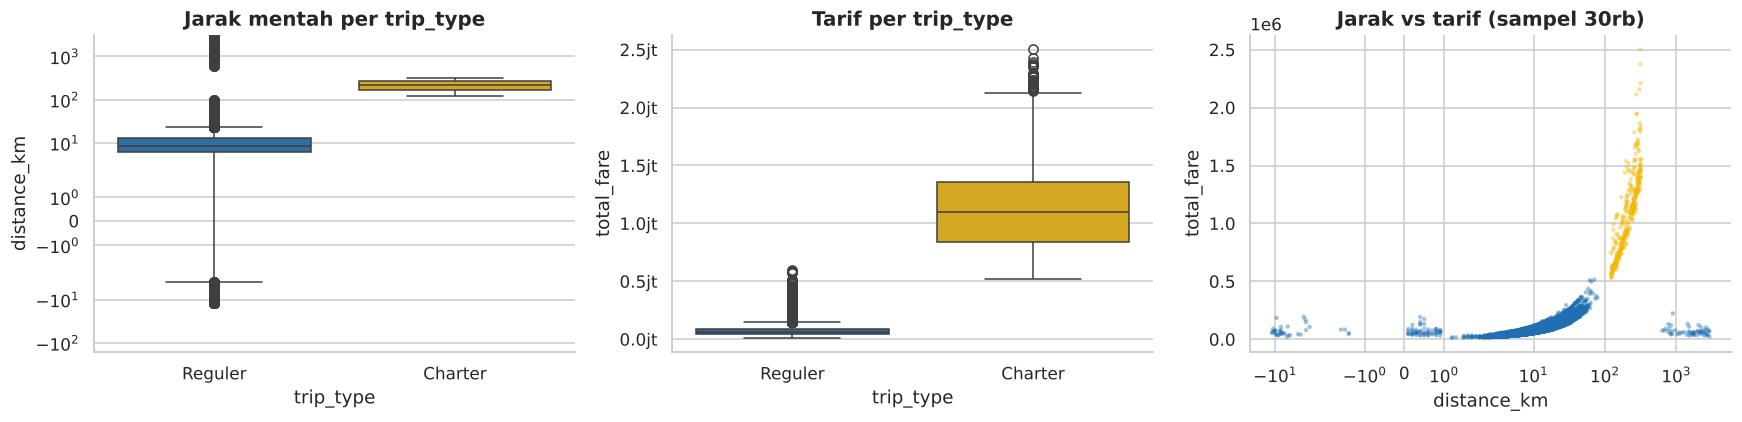

trip_type                    Charter    Reguler
distance_km       count     3,544.00 314,554.00
                  mean        219.89      13.74
                  std          58.31      78.15
                  min         120.20     -12.00
                  25%         167.50       6.10
                  50%         219.65       8.60
                  75%         271.10      12.80
                  max         320.00   2,999.20
total_fare        count     3,544.00 314,554.00
                  mean  1,121,472.35  71,544.28
                  std     349,324.66  40,595.50
                  min     519,500.00  14,000.00
                  25%     838,250.00  44,500.00
                  50%   1,098,750.00  60,000.00
                  75%   1,355,500.00  85,000.00
                  max   2,503,500.00 598,500.00
trip_duration_min count     3,544.00 314,554.00
                  mean        246.25      31.72
                  std          69.16      14.45
                  min         111.67       3.33
                  25%         188.75      21.57
                  50%         242.93      28.83
                  75%         299.17      38.58
                  max         469.05     194.72

In [16]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.boxplot(data=trips, x='trip_type', y='distance_km', ax=ax[0], palette=[BLUE,AMBER]); ax[0].set_title('Jarak mentah per trip_type'); ax[0].set_yscale('symlog')
sns.boxplot(data=trips, x='trip_type', y='total_fare', ax=ax[1], palette=[BLUE,AMBER]); ax[1].set_title('Tarif per trip_type'); ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p:f'{v/1e6:.1f}jt'))
s = trips.sample(30000, random_state=1)
ax[2].scatter(s.distance_km, s.total_fare, s=4, alpha=.3, c=np.where(s.trip_type=='Charter',AMBER,BLUE)); ax[2].set_xscale('symlog'); ax[2].set_title('Jarak vs tarif (sampel 30rb)'); ax[2].set_xlabel('distance_km'); ax[2].set_ylabel('total_fare')
plt.tight_layout(); plt.show()
display(trips.groupby('trip_type')[['distance_km','total_fare','trip_duration_min']].describe().T)

In [17]:
# Outlier dengan metode IQR — dihitung terpisah per trip_type
def iqr_flag(x):
    q1, q3 = x.quantile([.25,.75]); i = q3-q1
    return (x < q1-1.5*i) | (x > q3+1.5*i)
for col in ['distance_km','total_fare']:
    allf = iqr_flag(trips[col]).sum()
    per  = trips.groupby('trip_type')[col].transform(lambda x: iqr_flag(x)).sum()
    print(f'{col}: outlier IQR global = {allf:,} | IQR per trip_type = {per:,}')

distance_km: outlier IQR global = 26,454 | IQR per trip_type = 25,123
total_fare: outlier IQR global = 20,941 | IQR per trip_type = 18,685


**Insight:** jika IQR dihitung secara global, hampir semua trip **Charter** (120–320 km, Rp0,5–2,5 jt, durasi 2–8 jam) akan dianggap outlier — padahal itu **karakteristik layanan charter yang sah**. Maka outlier dievaluasi **per trip_type** dan dengan **logika bisnis** (konsistensi jarak–tarif).

In [18]:
reg = trips.trip_type=='Reguler'
print('Reguler jarak negatif   :', (reg & (trips.distance_km<0)).sum())
print('Reguler jarak > 200 km  :', (reg & (trips.distance_km>200)).sum())
print('Reguler jarak 50–200 km :', (reg & trips.distance_km.between(50,200)).sum())
display(trips[reg & trips.distance_km.between(50,200)].pickup_zone_type.value_counts().head(3))
display(trips[reg & (trips.distance_km>200)][['distance_km','total_fare','trip_duration_min']].describe().T)

Reguler jarak negatif   : 505
Reguler jarak > 200 km  : 516
Reguler jarak 50–200 km : 605


pickup_zone_type
Airport    598
Other        6
Mall         1
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
distance_km,516.00,"1,808.18",681.87,600.40,"1,221.12","1,798.10","2,398.10","2,999.20"
total_fare,516.00,"71,297.48","42,719.54","20,500.00","44,500.00","59,500.00","85,000.00","414,000.00"
trip_duration_min,516.00,32.27,15.87,7.73,21.76,29.07,39.00,190.27


Trip reguler > 200 km punya **tarif median Rp59.500 dan durasi median 29 menit** — sama persis dengan trip dalam kota biasa. Jarak 600–3.000 km dalam 30 menit mustahil → **error sensor odometer**. Sebaliknya, trip reguler 50–200 km mayoritas dari **Bandara** dengan tarif proporsional → **valid**.

Untuk jarak negatif, apakah cukup dibalik tandanya (`abs`)? Diuji dengan model tarif–jarak:

In [19]:
# Model tarif = base + rate * km per service_type, dilatih pada trip reguler yang valid
clean_mask = reg & trips.distance_km.between(0.1, 200)
fare_model = {}
for svc, g in trips[clean_mask].groupby('service_type'):
    rate, base = np.polyfit(g.distance_km, g.total_fare, 1)
    r2 = np.corrcoef(g.distance_km, g.total_fare)[0,1]**2
    fare_model[svc] = (rate, base)
    neg = trips[reg & (trips.distance_km<0) & (trips.service_type==svc)]
    implied = (neg.total_fare-base)/rate
    print(f'{svc:11s} tarif ≈ Rp{base:,.0f} + Rp{rate:,.0f}/km | R²={r2:.3f} | korelasi |jarak negatif| vs jarak implisit tarif = {np.corrcoef(-neg.distance_km, implied)[0,1]:.2f}')

Bluebird    tarif ≈ Rp14,610 + Rp4,725/km | R²=0.974 | korelasi |jarak negatif| vs jarak implisit tarif = 0.08


E-Cabbie    tarif ≈ Rp14,180 + Rp4,460/km | R²=0.976 | korelasi |jarak negatif| vs jarak implisit tarif = -0.02
Goldenbird  tarif ≈ Rp25,925 + Rp7,267/km | R²=0.972 | korelasi |jarak negatif| vs jarak implisit tarif = -0.10
Silverbird  tarif ≈ Rp18,883 + Rp5,854/km | R²=0.973 | korelasi |jarak negatif| vs jarak implisit tarif = -0.02


**Hasil:** model tarif sangat kuat (**R² ≈ 0,97**), tetapi nilai absolut jarak negatif **tidak berkorelasi** dengan jarak implisit dari tarif (r ≈ 0). Artinya angka negatif adalah *noise* sensor, bukan sekadar salah tanda → `abs()` **tidak tepat**.

**Keputusan:** untuk 505 trip jarak negatif dan 516 trip reguler > 200 km, jarak **diimputasi dari tarif** menggunakan model per kategori layanan (tarif tetap valid karena dihitung argometer). Baris tidak dibuang agar hitungan ritase & pendapatan tetap utuh. Trip Charter dipertahankan apa adanya.

In [20]:
bad_dist = reg & ((trips.distance_km<0) | (trips.distance_km>200))
trips['flag_distance_error'] = bad_dist
trips['distance_km_clean'] = trips.distance_km
for svc,(rate,base) in fare_model.items():
    m = bad_dist & (trips.service_type==svc)
    trips.loc[m,'distance_km_clean'] = ((trips.loc[m,'total_fare']-base)/rate).clip(lower=1).round(1)
print('Trip diimputasi:', bad_dist.sum())
display(trips.groupby('trip_type')['distance_km_clean'].describe().T)

Trip diimputasi: 1021


trip_type,Charter,Reguler
count,"3,544.00","314,554.00"
mean,219.89,10.82
std,58.31,7.46
min,120.20,0.10
25%,167.50,6.10
50%,219.65,8.60
75%,271.10,12.80
max,320.00,100.70


## <span style="color:#0B4F8A">3.7 Konsistensi antar tabel</span>

In [21]:
checks = {
 'trip.shift_id ada di shifts'          : trips.shift_id.isin(shifts.shift_id).mean(),
 'trip.driver_id ada di drivers'        : trips.driver_id.isin(drivers.driver_id).mean(),
 'driver trip = driver shift'           : (tmp.driver_id==tmp.driver_id_shift).mean(),
 'trip.company_id ada di corp (eVoucher)': trips.company_id.dropna().isin(corp.company_id).mean(),
 'request.matched_trip_id ada di trips' : requests.matched_trip_id.dropna().isin(trips.trip_id).mean(),
 'matched_trip_id unik'                 : 1-requests.matched_trip_id.dropna().duplicated().mean(),
 'shift.driver_id ada di drivers'       : shifts.driver_id.isin(drivers.driver_id).mean(),
 'driver.pool_id ada di pools'          : drivers.pool_id.isin(pools.pool_id).mean(),
}
cnt = trips.groupby('shift_id').size()
checks['trip_count shift = jumlah trip aktual'] = (shifts.trip_count == shifts.shift_id.map(cnt).fillna(0)).mean()
pd.Series(checks, name='% valid').mul(100).round(2).to_frame()

,% valid
trip.shift_id ada di shifts,100.00
trip.driver_id ada di drivers,100.00
driver trip = driver shift,100.00
trip.company_id ada di corp (eVoucher),100.00
request.matched_trip_id ada di trips,100.00
matched_trip_id unik,100.00
shift.driver_id ada di drivers,100.00
driver.pool_id ada di pools,100.00
trip_count shift = jumlah trip aktual,100.00


**Hasil:** seluruh relasi antar tabel **100% valid**, dan `trip_count` di tabel shift **identik** dengan jumlah trip aktual di tabel trips → tabel aman di-join, dan `trip_count` dapat dipakai sebagai ukuran ritase.

In [22]:
cleaning_log = pd.DataFrame([
 ['Tipe data','Kolom waktu bertipe teks','6 kolom','Konversi ke datetime'],
 ['Duplikat','Baris/PK ganda','0','Tidak ada tindakan'],
 ['Missing values','company_id kosong (non-eVoucher)', f'{trips.company_id.isna().sum():,}','Dibiarkan — sesuai alur bisnis'],
 ['Missing values','matched_trip_id/wait_time kosong (Cancelled)', f'{requests.matched_trip_id.isna().sum():,}','Dibiarkan — sesuai alur bisnis'],
 ['Formatting','Variasi penulisan service_type','22 → 4','Mapping ke 4 kategori; tervalidasi vs tipe armada'],
 ['Anomali waktu','Argo menyala sebelum booking', f'{trips.flag_time_error.sum():,}','Flag; pickup_wait = NaN; trip dipertahankan'],
 ['Anomali waktu','Argo di luar jam shift', f'{trips.flag_outside_shift.sum():,}','Flag; dipertahankan'],
 ['Anomali jarak','Jarak negatif (reguler)', f'{(reg&(trips.distance_km<0)).sum():,}','Imputasi dari model tarif (R²≈0,97)'],
 ['Anomali jarak','Jarak > 200 km (reguler)', f'{(reg&(trips.distance_km>200)).sum():,}','Imputasi dari model tarif'],
 ['Outlier','Charter 120–320 km, Rp0,5–2,5 jt', f'{(trips.trip_type=="Charter").sum():,}','Valid — dipertahankan, dianalisis terpisah'],
 ['Konsistensi','Relasi antar 6 tabel','100% valid','Aman di-join'],
], columns=['Kategori','Masalah','Jumlah','Penanganan'])
cleaning_log

,Kategori,Masalah,Jumlah,Penanganan
0,Tipe data,Kolom waktu bertipe teks,6 kolom,Konversi ke datetime
1,Duplikat,Baris/PK ganda,0,Tidak ada tindakan
2,Missing values,company_id kosong (non-eVoucher),"260,740",Dibiarkan — sesuai alur bisnis
3,Missing values,matched_trip_id/wait_time kosong (Cancelled),"19,397",Dibiarkan — sesuai alur bisnis
4,Formatting,Variasi penulisan service_type,22 → 4,Mapping ke 4 kategori; tervalidasi vs tipe armada
5,Anomali waktu,Argo menyala sebelum booking,"6,595",Flag; pickup_wait = NaN; trip dipertahankan
6,Anomali waktu,Argo di luar jam shift,96,Flag; dipertahankan
7,Anomali jarak,Jarak negatif (reguler),505,"Imputasi dari model tarif (R²≈0,97)"
8,Anomali jarak,Jarak > 200 km (reguler),516,Imputasi dari model tarif
9,Outlier,"Charter 120–320 km, Rp0,5–2,5 jt","3,544","Valid — dipertahankan, dianalisis terpisah"


<a id="fe"></a>
# <span style="color:#0B4F8A">4. Feature Engineering & Data Merging</span>

In [23]:
# --- Shift level (unit analisis ritase) ---
sh = shifts.merge(drivers, on='driver_id').merge(pools, on='pool_id')
sh['shift_minutes'] = (sh.clock_out_time - sh.clock_in_time).dt.total_seconds()/60
sh['utilization']   = 1 - sh.total_idle_minutes/sh.shift_minutes          # porsi waktu shift yang produktif
sh['clock_in_hour'] = sh.clock_in_time.dt.hour
sh['shift_slot']    = np.where(sh.clock_in_hour<12, 'Pagi (05–08)', 'Malam (18–22)')
sh['tenure_years']  = (pd.Timestamp('2023-10-01') - sh.join_date).dt.days/365.25
sh['zero_trip']     = sh.trip_count.eq(0)
rev_shift = trips.groupby('shift_id').total_fare.sum()
sh['revenue'] = sh.shift_id.map(rev_shift).fillna(0)

# --- Trip level ---
tr = trips.merge(drivers[['driver_id','pool_id']], on='driver_id').merge(pools[['pool_id','pool_name']], on='pool_id')
tr['hour'] = tr.meter_start_time.dt.hour
tr['dow']  = tr.meter_start_time.dt.dayofweek
tr['is_weekend'] = tr.dow>=5
tr['is_night']   = (tr.hour>=22) | (tr.hour<5)          # 22.00–04.59
tr['is_evoucher']= tr.payment_method.eq('eVoucher Corporate')

# --- Request level ---
rq = requests.copy()
rq['hour'] = rq.requested_time.dt.hour
rq['dow']  = rq.requested_time.dt.dayofweek
rq['fulfilled'] = rq.status.eq('Fulfilled')
rq['peak'] = rq.hour.isin([7,8,17,18])
print(sh.shape, tr.shape, rq.shape)

(252524, 26) (318098, 28) (289622, 11)


<a id="da"></a>
# <span style="color:#0B4F8A">5. Data Analysis</span>

## <span style="color:#0B4F8A">5.0 Gambaran umum operasional (EDA)</span>

In [24]:
RES['n_drivers']=int(drivers.shape[0]); RES['n_pools']=int(pools.shape[0]); RES['n_corp']=int(corp.shape[0])
RES['n_trips']=int(len(trips)); RES['n_shifts']=int(len(shifts)); RES['n_requests']=int(len(requests)); RES['n_days']=int(N_DAYS)
RES['revenue_total_b']=trips.total_fare.sum()/1e9
RES['rit_mean']=sh.trip_count.mean(); RES['target_pct']=sh.ritase_target_met.mean()*100
RES['idle_mean']=sh.total_idle_minutes.mean(); RES['shift_min_mean']=sh.shift_minutes.mean()
RES['idle_pct']=RES['idle_mean']/RES['shift_min_mean']*100; RES['util_mean']=sh.utilization.mean()*100
RES['zero_pct']=sh.zero_trip.mean()*100
RES['unmet_n']=int((~rq.fulfilled).sum()); RES['unmet_pct']=(~rq.fulfilled).mean()*100
RES['nodriver_n']=int((rq.status=='Cancelled-No Driver').sum()); RES['timeout_n']=int((rq.status=='Cancelled-Timeout').sum())
RES['wait_mean']=rq.wait_time_minutes.mean()
RES['fare_med_reg']=trips[trips.trip_type=='Reguler'].total_fare.median()
RES['dist_med_reg']=trips[trips.trip_type=='Reguler'].distance_km_clean.median()
kpi = {k:RES[k] for k in ['n_trips','n_shifts','n_requests','revenue_total_b','rit_mean','target_pct','idle_mean','idle_pct','util_mean','zero_pct','unmet_n','unmet_pct','wait_mean','fare_med_reg','dist_med_reg']}
pd.Series(kpi).round(2).to_frame('nilai')

,nilai
n_trips,"318,098.00"
n_shifts,"252,524.00"
n_requests,"289,622.00"
revenue_total_b,26.48
rit_mean,1.26
target_pct,0.35
idle_mean,460.74
idle_pct,90.34
util_mean,9.74
zero_pct,30.65


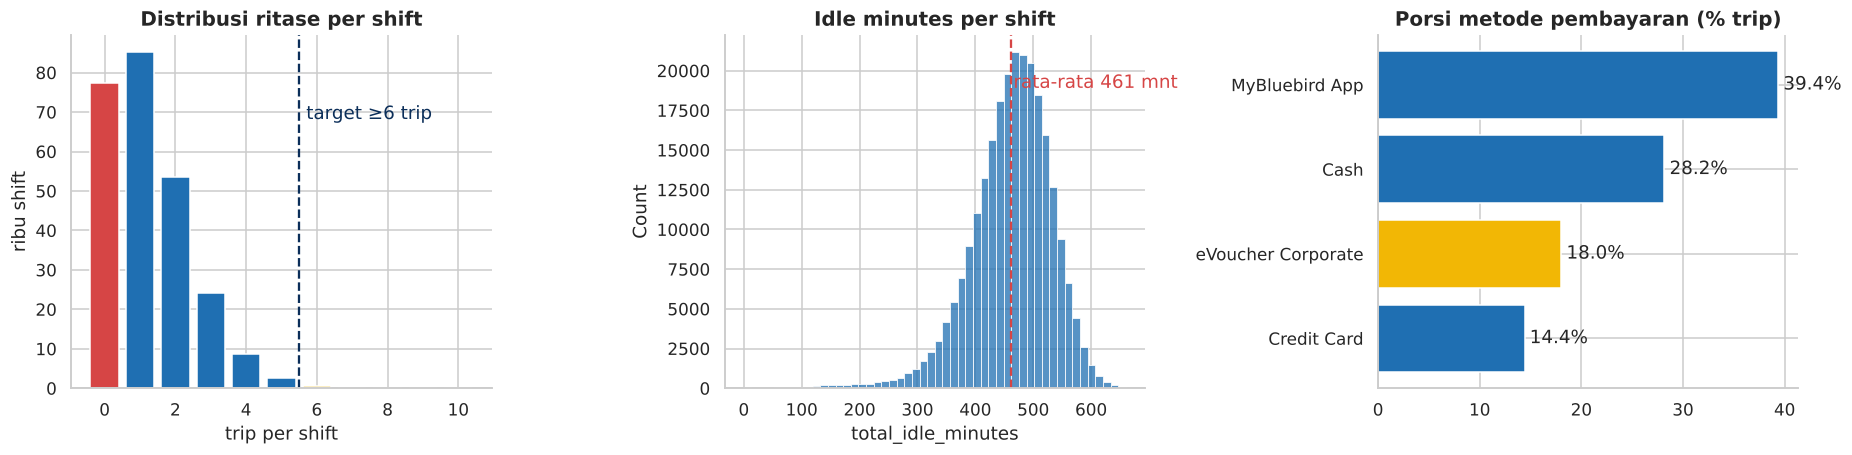

In [25]:
fig, ax = plt.subplots(1,3, figsize=(17,4.3))
vc = sh.trip_count.value_counts().sort_index()
ax[0].bar(vc.index, vc.values/1e3, color=[RED if i==0 else (AMBER if i>=6 else BLUE) for i in vc.index])
ax[0].axvline(5.5, ls='--', c=NAVY); ax[0].text(5.7, vc.max()/1e3*.8, 'target ≥6 trip', color=NAVY)
ax[0].set_title('Distribusi ritase per shift'); ax[0].set_xlabel('trip per shift'); ax[0].set_ylabel('ribu shift')
sns.histplot(sh.total_idle_minutes, bins=50, color=BLUE, ax=ax[1]); ax[1].set_title('Idle minutes per shift'); ax[1].axvline(sh.total_idle_minutes.mean(), c=RED, ls='--'); ax[1].text(sh.total_idle_minutes.mean()+5, ax[1].get_ylim()[1]*.85, f"rata-rata {sh.total_idle_minutes.mean():.0f} mnt", color=RED)
pm = trips.payment_method.value_counts(normalize=True)*100
ax[2].barh(pm.index, pm.values, color=[AMBER if 'eVoucher' in i else BLUE for i in pm.index]); ax[2].invert_yaxis()
for i,v in enumerate(pm.values): ax[2].text(v+.5,i,f'{v:.1f}%',va='center')
ax[2].set_title('Porsi metode pembayaran (% trip)')
plt.tight_layout(); plt.show()

**Insight EDA:** 31% shift berakhir **tanpa satu trip pun**, dan hanya 0.35% shift mencapai target ≥6 trip. Rata-rata utilisasi waktu shift hanya **9.7%** — sangat jauh dari acuan utilisasi armada ~70% yang pernah dipatok manajemen (2018). eVoucher korporat menyumbang ±18% trip — porsi yang material untuk dikendalikan.

## <span style="color:#0B4F8A">5.1 Fleet Optimization</span>

### <span style="color:#0B4F8A">BQ1 — Bagaimana ritase & idle time bervariasi antar pool?</span>

In [26]:
pool_tbl = sh.groupby(['pool_name','primary_zone_affinity']).agg(
    pengemudi=('driver_id','nunique'), shift=('shift_id','size'),
    ritase=('trip_count','mean'), pct_target=('ritase_target_met','mean'),
    pct_zero_trip=('zero_trip','mean'), idle_min=('total_idle_minutes','mean'),
    utilisasi=('utilization','mean'), revenue_per_shift=('revenue','mean')).reset_index()
pool_tbl[['pct_target','pct_zero_trip','utilisasi']] *= 100
pool_tbl = pool_tbl.merge(pools[['pool_name','distance_to_cbd_km','distance_to_soetta_km']], on='pool_name').sort_values('ritase')
pool_tbl

,pool_name,primary_zone_affinity,pengemudi,shift,ritase,pct_target,pct_zero_trip,idle_min,utilisasi,revenue_per_shift,distance_to_cbd_km,distance_to_soetta_km
1,Pool Bandara Soetta,Airport-heavy,644,40093,0.97,0.14,40.47,470.36,7.85,"95,984.89",28.00,3.50
3,Pool Halim,Mixed,425,26557,1.24,0.25,31.23,462.11,9.42,"102,853.22",12.00,41.00
0,Pool BSD,Mixed,485,30340,1.25,0.34,30.50,462.20,9.47,"102,519.96",26.00,32.00
2,Pool Ciputat,Mixed,520,32287,1.25,0.31,30.53,461.63,9.58,"104,564.00",18.00,35.00
7,Pool Puri,Mixed,454,28104,1.26,0.28,30.15,461.42,9.58,"103,716.70",15.00,22.00
4,Pool Kelapa Gading,CBD-heavy,515,32236,1.39,0.48,26.82,455.78,10.72,"107,898.06",16.00,26.00
6,Pool Mampang,CBD-heavy,464,28910,1.40,0.51,26.34,455.07,10.82,"111,541.47",8.00,30.00
5,Pool Kramat Jati,CBD-heavy,548,33997,1.40,0.54,26.55,455.13,10.87,"111,627.73",14.00,38.00


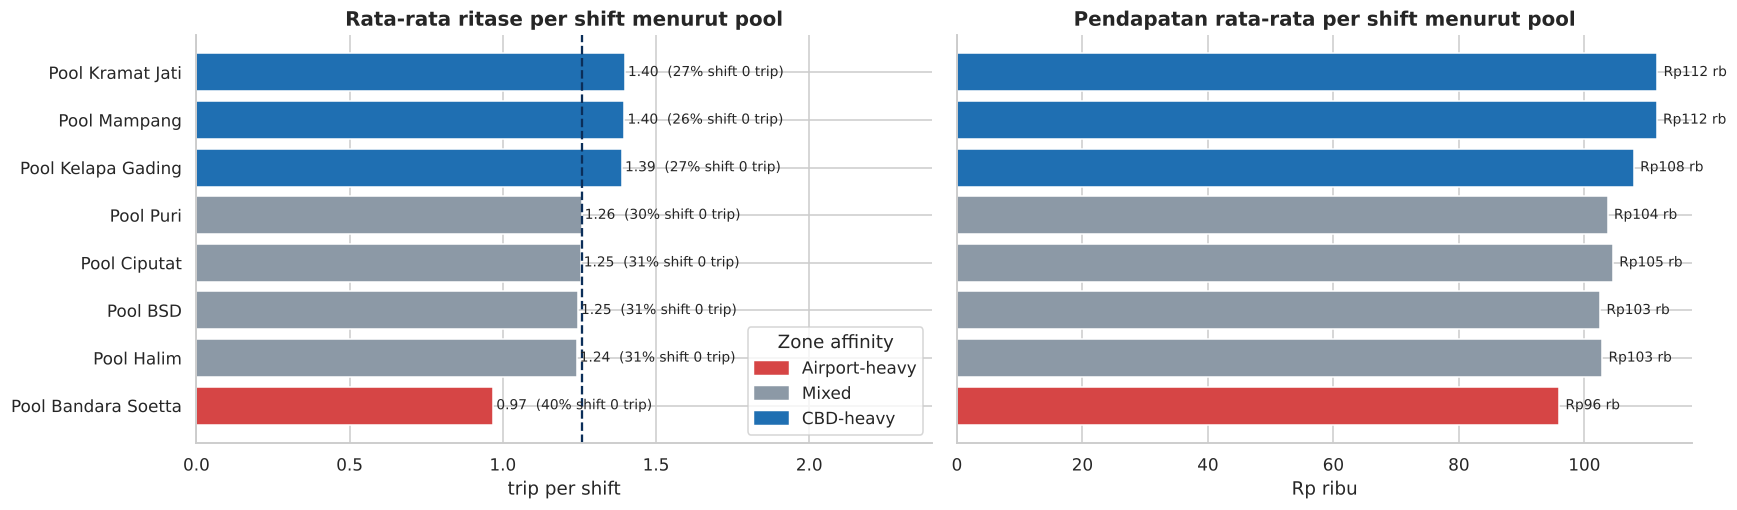

In [27]:
colors = {'Airport-heavy':RED,'Mixed':GREY,'CBD-heavy':BLUE}
fig, ax = plt.subplots(1,2, figsize=(16,4.8))
p = pool_tbl.sort_values('ritase')
ax[0].barh(p.pool_name, p.ritase, color=[colors[z] for z in p.primary_zone_affinity])
for i,(v,z) in enumerate(zip(p.ritase,p.pct_zero_trip)): ax[0].text(v+.01,i,f'{v:.2f}  ({z:.0f}% shift 0 trip)',va='center',fontsize=9)
ax[0].axvline(sh.trip_count.mean(), c=NAVY, ls='--'); ax[0].set_xlim(0,2.4)
ax[0].set_title('Rata-rata ritase per shift menurut pool'); ax[0].set_xlabel('trip per shift')
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=c,label=k) for k,c in colors.items()], title='Zone affinity', loc='lower right', frameon=True)
ax[1].barh(p.pool_name, p.revenue_per_shift/1e3, color=[colors[z] for z in p.primary_zone_affinity])
for i,v in enumerate(p.revenue_per_shift/1e3): ax[1].text(v+1,i,f'Rp{v:,.0f} rb',va='center',fontsize=9)
ax[1].set_title('Pendapatan rata-rata per shift menurut pool'); ax[1].set_xlabel('Rp ribu'); ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

In [28]:
# Uji statistik: apakah distribusi ritase berbeda signifikan antar pool? (data diskrit & tidak normal → Kruskal-Wallis)
groups = [g.trip_count.values for _,g in sh.groupby('pool_name')]
H_, p_ = stats.kruskal(*groups)
print(f'Kruskal-Wallis ritase ~ pool: H={H_:,.1f}, p={p_:.2e}')
# Post-hoc: pool bandara vs pool CBD-heavy
a = sh[sh.primary_zone_affinity=='Airport-heavy'].trip_count; b = sh[sh.primary_zone_affinity=='CBD-heavy'].trip_count; m = sh[sh.primary_zone_affinity=='Mixed'].trip_count
for n1,x,n2,y in [('Airport-heavy',a,'CBD-heavy',b),('Mixed',m,'CBD-heavy',b),('Airport-heavy',a,'Mixed',m)]:
    U,pp = stats.mannwhitneyu(x,y); print(f'Mann-Whitney {n1} vs {n2}: p={pp:.2e}, median {x.median()} vs {y.median()}, mean {x.mean():.2f} vs {y.mean():.2f}')
RES['kw_pool_H']=H_; RES['kw_pool_p']=p_; RES['mw_air_cbd_p']=stats.mannwhitneyu(a,b)[1]

Kruskal-Wallis ritase ~ pool: H=3,811.0, p=0.00e+00
Mann-Whitney Airport-heavy vs CBD-heavy: p=0.00e+00, median 1.0 vs 1.0, mean 0.97 vs 1.39
Mann-Whitney Mixed vs CBD-heavy: p=1.87e-160, median 1.0 vs 1.0, mean 1.25 vs 1.39
Mann-Whitney Airport-heavy vs Mixed: p=0.00e+00, median 1.0 vs 1.0, mean 0.97 vs 1.25


In [29]:
cgk = pool_tbl.set_index('pool_name').loc['Pool Bandara Soetta']
best = pool_tbl.ritase.max()
RES.update(cgk_rit=cgk.ritase, cgk_zero=cgk.pct_zero_trip, cgk_drivers=int(cgk.pengemudi), cgk_shift_share=cgk['shift']/len(sh)*100,
           cbdheavy_rit=sh[sh.primary_zone_affinity=='CBD-heavy'].trip_count.mean(), mixed_rit=sh[sh.primary_zone_affinity=='Mixed'].trip_count.mean(),
           best_rit=best, gap_pct=(best/cgk.ritase-1)*100, cgk_rev=cgk.revenue_per_shift, best_rev=pool_tbl.revenue_per_shift.max())
RES['pool_table'] = pool_tbl[['pool_name','primary_zone_affinity','pengemudi','ritase','pct_zero_trip','idle_min','utilisasi','revenue_per_shift']].round(3).to_dict('records')
print(f"Gap ritase pool terbaik vs Soetta: {RES['gap_pct']:.0f}%")

Gap ritase pool terbaik vs Soetta: 44%


**Insight BQ1:**
- Perbedaan ritase antar pool **signifikan secara statistik** (Kruskal-Wallis p < 0,001) dan membentuk **3 klaster** sesuai *zone affinity*: **CBD-heavy ≈ 1.39**, **Mixed ≈ 1.25**, **Airport-heavy (Soetta) = 0.97** trip/shift.
- **Pool Bandara Soetta adalah pool terbesar** (644 pengemudi, 16% dari seluruh shift) **namun paling tidak produktif**: 40% shift tanpa trip, ritase 44% di bawah pool terbaik, pendapatan per shift Rp95,985 vs Rp111,628.
- Idle time di semua pool sama-sama tinggi (455–470 menit) → masalah ritase bersifat **sistemik**, dengan pool bandara sebagai titik terparah.

### <span style="color:#0B4F8A">BQ2 — Faktor apa yang menjelaskan variasi ritase?</span>

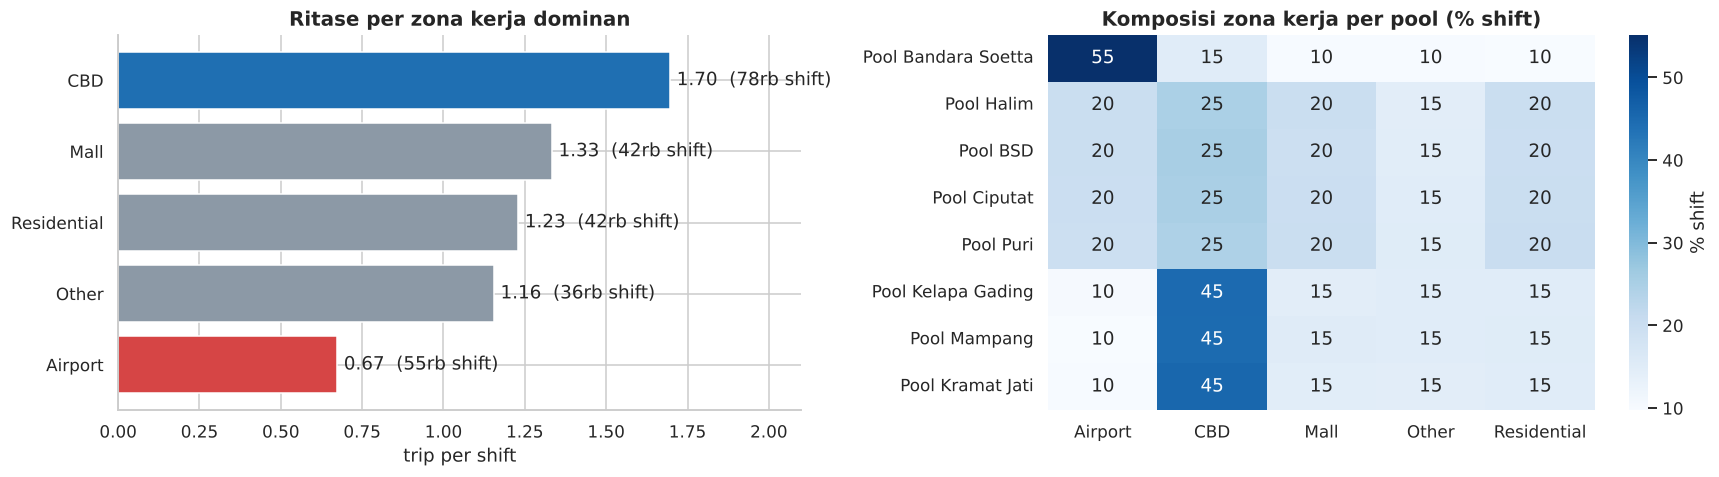

In [30]:
fig, ax = plt.subplots(1,2, figsize=(16,4.5))
z = sh.groupby('dominant_zone_worked').agg(rit=('trip_count','mean'), n=('shift_id','size')).sort_values('rit')
ax[0].barh(z.index, z.rit, color=[RED if i=='Airport' else (BLUE if i=='CBD' else GREY) for i in z.index])
for i,(v,n) in enumerate(zip(z.rit,z.n)): ax[0].text(v+.02,i,f'{v:.2f}  ({n/1e3:.0f}rb shift)',va='center')
ax[0].set_title('Ritase per zona kerja dominan'); ax[0].set_xlabel('trip per shift'); ax[0].set_xlim(0,2.1)
ct = pd.crosstab(sh.pool_name, sh.dominant_zone_worked, normalize='index')*100
ct = ct.loc[pool_tbl.sort_values('ritase').pool_name]
sns.heatmap(ct, annot=True, fmt='.0f', cmap='Blues', ax=ax[1], cbar_kws={'label':'% shift'}); ax[1].set_title('Komposisi zona kerja per pool (% shift)'); ax[1].set_xlabel(''); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

In [31]:
# Faktor karakteristik pengemudi & pool — korelasi Spearman dengan ritase
fac = sh[['trip_count','driver_rating','tenure_years','shift_minutes','distance_to_cbd_km','distance_to_soetta_km']]
corr = fac.corr(method='spearman')['trip_count'].drop('trip_count').round(3)
display(corr.to_frame('Spearman ρ vs ritase'))
cat = pd.concat([sh.groupby('vehicle_type_assigned').trip_count.mean().rename('ritase').to_frame().assign(faktor='Tipe armada'),
                 sh.groupby('employment_status').trip_count.mean().rename('ritase').to_frame().assign(faktor='Status kepegawaian'),
                 sh.groupby('shift_slot').trip_count.mean().rename('ritase').to_frame().assign(faktor='Slot shift'),
                 sh.groupby(sh.shift_date.dt.dayofweek>=5).trip_count.mean().rename('ritase').rename({False:'Hari kerja',True:'Akhir pekan'}).to_frame().assign(faktor='Hari')])
display(cat.round(3))
U,p_emp = stats.mannwhitneyu(sh[sh.employment_status=='Tetap'].trip_count, sh[sh.employment_status=='Mitra'].trip_count)
H_v,p_veh = stats.kruskal(*[g.trip_count for _,g in sh.groupby('vehicle_type_assigned')])
H_z,p_zone = stats.kruskal(*[g.trip_count for _,g in sh.groupby('dominant_zone_worked')])
U,p_slot = stats.mannwhitneyu(sh[sh.shift_slot.str.startswith('Pagi')].trip_count, sh[~sh.shift_slot.str.startswith('Pagi')].trip_count)
print(f'Tetap vs Mitra p={p_emp:.3f} | Tipe armada p={p_veh:.3f} | Zona kerja p={p_zone:.2e} | Slot shift p={p_slot:.2e}')
RES.update(H_zone=H_z, p_zone=p_zone, p_slot=p_slot, zone_rit=z.rit.round(3).to_dict(), rho_rating=corr['driver_rating'], rho_tenure=corr['tenure_years'], rho_cbd=corr['distance_to_cbd_km'],
           p_emp=p_emp, p_veh=p_veh, airport_rit=z.rit['Airport'], cbd_rit=z.rit['CBD'],
           slot_pagi=sh[sh.shift_slot.str.startswith('Pagi')].trip_count.mean(), slot_malam=sh[~sh.shift_slot.str.startswith('Pagi')].trip_count.mean())

,Spearman ρ vs ritase
driver_rating,-0.00
tenure_years,-0.00
shift_minutes,-0.00
distance_to_cbd_km,-0.09
distance_to_soetta_km,0.06


,ritase,faktor
Electric,1.25,Tipe armada
Golden,1.26,Tipe armada
Reguler,1.26,Tipe armada
Silver,1.27,Tipe armada
Mitra,1.26,Status kepegawaian
Tetap,1.26,Status kepegawaian
Malam (18–22),1.01,Slot shift
Pagi (05–08),1.31,Slot shift
Hari kerja,1.26,Hari
Akhir pekan,1.26,Hari


Tetap vs Mitra p=0.434 | Tipe armada p=0.279 | Zona kerja p=0.00e+00 | Slot shift p=0.00e+00


**Insight BQ2:**
- **Karakteristik pengemudi TIDAK menjelaskan ritase**: rating (ρ = -0.003), masa kerja (ρ = -0.000), status Tetap vs Mitra (p = 0.43) dan tipe armada (p = 0.28) tidak signifikan. Ritase rendah **bukan masalah kinerja individu** → solusi berupa pelatihan/sanksi pengemudi kurang tepat sasaran.
- **Yang menentukan adalah DI MANA pengemudi bekerja.** Shift di zona **CBD** menghasilkan **1.70** trip, sementara shift di **Bandara** hanya **0.67** (2,5× lebih rendah). Pool Soetta menempatkan 55% shift-nya di Bandara — itulah sebab ritasenya terendah.
- Shift malam (mulai 18–22) lebih rendah ritasenya (1.01) daripada shift pagi (1.31) karena demand malam sangat kecil (lihat BQ3).

### <span style="color:#0B4F8A">BQ3 — Apakah armada aktif per jam sesuai pola permintaan?</span>

In [32]:
# Hitung rata-rata jumlah pengemudi aktif pada setiap jam (sampling di menit ke-30 setiap jam)
grid = pd.date_range(sh.clock_in_time.min().floor('D'), sh.clock_out_time.max().ceil('D'), freq='h') + pd.Timedelta(minutes=30)
ci = np.sort(sh.clock_in_time.values); co = np.sort(sh.clock_out_time.values)
active = np.searchsorted(ci, grid.values, side='right') - np.searchsorted(co, grid.values, side='right')
hourly = pd.DataFrame({'armada_aktif': pd.Series(active, index=grid).groupby(grid.hour).mean(),
                       'permintaan': rq.groupby('hour').size()/N_DAYS,
                       'tak_terpenuhi': rq[~rq.fulfilled].groupby('hour').size()/N_DAYS})
hourly['permintaan_per_100_armada'] = hourly.permintaan/hourly.armada_aktif*100
hourly['fulfillment_%'] = (1-hourly.tak_terpenuhi/hourly.permintaan)*100
hourly.round(1)

,armada_aktif,permintaan,tak_terpenuhi,permintaan_per_100_armada,fulfillment_%
0,484.30,26.60,1.10,5.50,95.90
1,486.70,38.80,1.80,8.00,95.50
2,460.30,58.80,2.10,12.80,96.50
3,389.50,64.70,2.50,16.60,96.20
4,294.70,60.60,2.50,20.60,95.90
5,493.10,78.40,3.10,15.90,96.10
6,968.90,107.70,6.80,11.10,93.70
7,"1,465.90",153.70,33.80,10.50,78.00
8,"2,011.70",192.70,43.30,9.60,77.60
9,"2,285.30",177.10,10.50,7.70,94.10


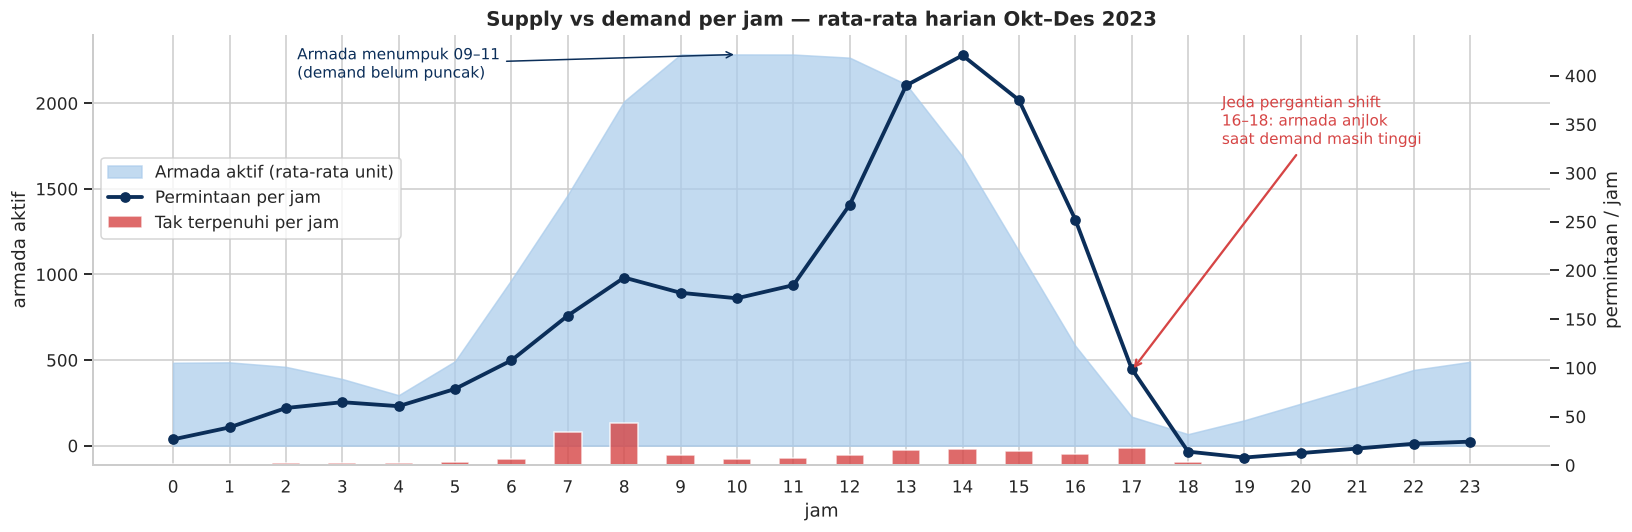

In [33]:
fig, ax1 = plt.subplots(figsize=(15,5))
ax1.fill_between(hourly.index, hourly.armada_aktif, color=SKY, alpha=.7, label='Armada aktif (rata-rata unit)')
ax1.set_ylabel('armada aktif'); ax1.set_xlabel('jam'); ax1.set_xticks(range(24))
ax2 = ax1.twinx(); ax2.plot(hourly.index, hourly.permintaan, color=NAVY, lw=2.5, marker='o', label='Permintaan per jam')
ax2.bar(hourly.index, hourly.tak_terpenuhi, color=RED, alpha=.8, width=.5, label='Tak terpenuhi per jam'); ax2.set_ylabel('permintaan / jam'); ax2.grid(False)
ax1.annotate('Armada menumpuk 09–11\n(demand belum puncak)', xy=(10,2285), xytext=(2.2,2150), arrowprops=dict(arrowstyle='->', color=NAVY), fontsize=10, color=NAVY)
ax2.annotate('Jeda pergantian shift\n16–18: armada anjlok\nsaat demand masih tinggi', xy=(17,97), xytext=(18.6,330), arrowprops=dict(arrowstyle='->', color=RED, lw=1.5), fontsize=10, color=RED)
h1,l1=ax1.get_legend_handles_labels(); h2,l2=ax2.get_legend_handles_labels(); ax2.legend(h1+h2,l1+l2,loc='center left', bbox_to_anchor=(0,.62), frameon=True)
plt.title('Supply vs demand per jam — rata-rata harian Okt–Des 2023'); plt.tight_layout(); plt.show()

In [34]:
print('Jam mulai shift:'); print(sh.clock_in_hour.value_counts().sort_index().to_string())
print(f"Durasi shift rata-rata: {sh.shift_minutes.mean()/60:.1f} jam → shift pagi (mulai 05–08) berakhir ±13.30–16.30")
RES.update(act_peak=hourly.armada_aktif.max(), act_peak_hour=int(hourly.armada_aktif.idxmax()), act_17=hourly.loc[17,'armada_aktif'],
           rpd_morning=hourly.loc[9:11,'permintaan_per_100_armada'].mean(), rpd_17=hourly.loc[17,'permintaan_per_100_armada'],
           dem_peak_hour=int(hourly.permintaan.idxmax()), dem_peak=hourly.permintaan.max(), dem_1316_share=hourly.loc[13:16,'permintaan'].sum()/hourly.permintaan.sum()*100,
           act_1316_share=hourly.loc[13:16,'armada_aktif'].sum()/hourly.armada_aktif.sum()*100,
           hourly=hourly.round(2).reset_index().rename(columns={'index':'hour'}).to_dict('records'))

Jam mulai shift:
clock_in_hour
5     52106
6     51951
7     51915
8     51988
18     8854
19     8892
20     8871
21     8946
22     9001
Durasi shift rata-rata: 8.5 jam → shift pagi (mulai 05–08) berakhir ±13.30–16.30


**Insight BQ3:**
- **Supply terlambat dari demand.** Armada aktif memuncak pukul 09–11 (≈2,285 unit) saat permintaan baru ±8 per 100 unit/jam. Demand justru memuncak pukul **13–16** (45% permintaan harian), ketika shift pagi mulai selesai.
- **Jeda pergantian shift 16–18:** semua shift pagi mulai 05–08 dan berlangsung ±8,5 jam, sementara shift malam baru mulai 18–22. Pukul 17.00 hanya ±169 unit aktif menghadapi ±97 permintaan/jam (**59 permintaan per 100 unit**, 6–8× lebih padat dari pagi).
- Sebaliknya, pukul 19–23 armada malam (250–490 unit) melayani < 25 permintaan/jam → **kelebihan supply malam**.
- Kesimpulan: masalahnya bukan kekurangan armada total, melainkan **jadwal shift yang tidak mengikuti kurva permintaan**.

## <span style="color:#0B4F8A">5.2 Unmet Demand</span>

### <span style="color:#0B4F8A">BQ4 — Pada jam & zona mana permintaan paling sering tidak terpenuhi?</span>

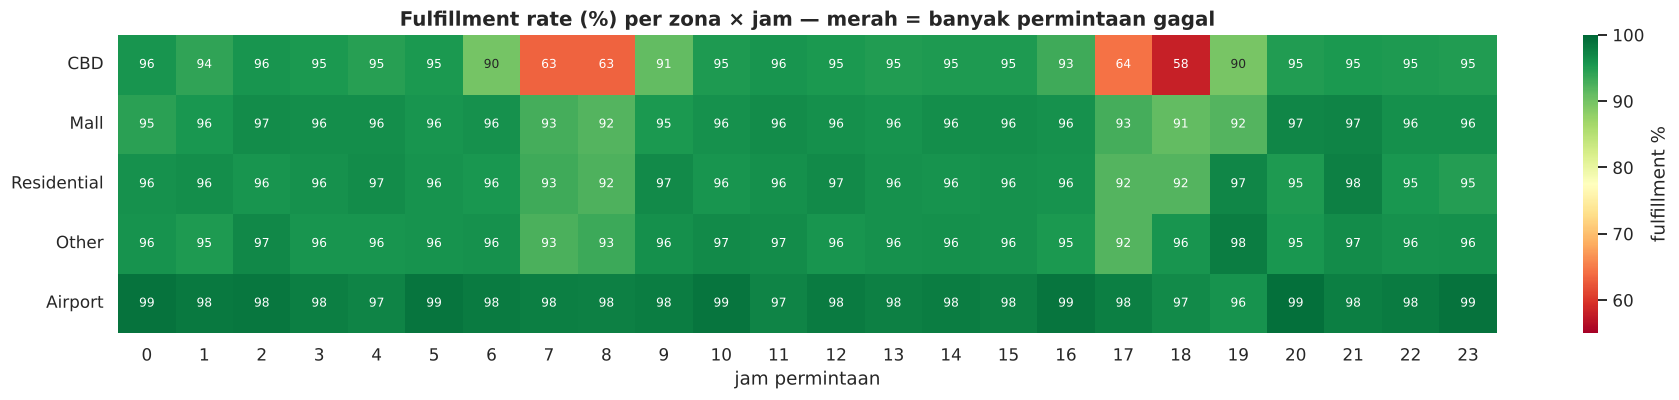

In [35]:
heat = rq.pivot_table(index='pickup_zone_type', columns='hour', values='fulfilled', aggfunc='mean')*100
heat = heat.loc[['CBD','Mall','Residential','Other','Airport']]
fig, ax = plt.subplots(figsize=(17,3.8))
sns.heatmap(heat, cmap='RdYlGn', vmin=55, vmax=100, annot=True, fmt='.0f', annot_kws={'size':8}, ax=ax, cbar_kws={'label':'fulfillment %'})
ax.set_title('Fulfillment rate (%) per zona × jam — merah = banyak permintaan gagal'); ax.set_xlabel('jam permintaan'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

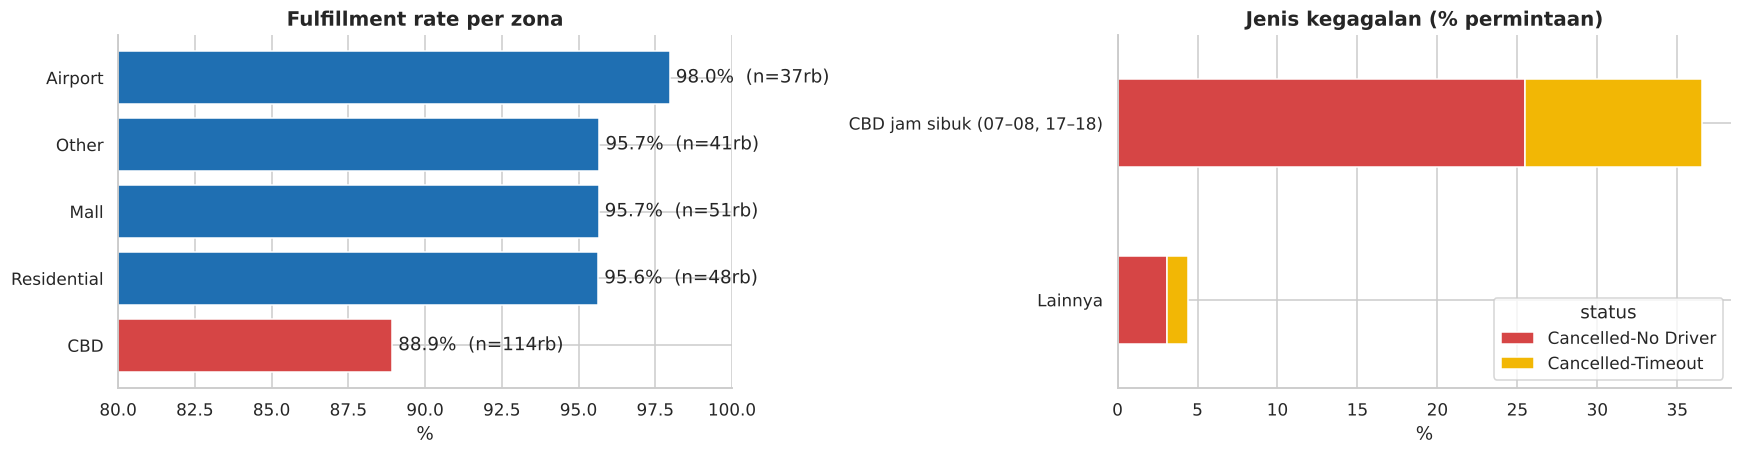

In [36]:
fig, ax = plt.subplots(1,2, figsize=(16,4.3))
zf = rq.groupby('pickup_zone_type').agg(n=('fulfilled','size'), fr=('fulfilled','mean')).sort_values('fr')
ax[0].barh(zf.index, zf.fr*100, color=[RED if i=='CBD' else BLUE for i in zf.index]); ax[0].set_xlim(80,100)
for i,(v,n) in enumerate(zip(zf.fr*100,zf.n)): ax[0].text(v+.2,i,f'{v:.1f}%  (n={n/1e3:.0f}rb)',va='center')
ax[0].set_title('Fulfillment rate per zona'); ax[0].set_xlabel('%')
st = pd.crosstab(rq.pickup_zone_type.eq('CBD') & rq.peak, rq.status)
st.index = ['Lainnya','CBD jam sibuk (07–08, 17–18)']
(st.div(st.sum(1),axis=0)*100)[['Cancelled-No Driver','Cancelled-Timeout']].plot.barh(stacked=True, color=[RED,AMBER], ax=ax[1])
ax[1].set_title('Jenis kegagalan (% permintaan)'); ax[1].set_xlabel('%'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

In [37]:
# Uji chi-square: status permintaan vs zona, dan vs (CBD × jam sibuk)
chi1 = stats.chi2_contingency(pd.crosstab(rq.pickup_zone_type, rq.fulfilled))
cbdpk = rq.pickup_zone_type.eq('CBD') & rq.peak
chi2_ = stats.chi2_contingency(pd.crosstab(cbdpk, rq.fulfilled))
print(f'Chi-square status ~ zona: χ²={chi1[0]:,.0f}, p={chi1[1]:.2e}')
print(f'Chi-square status ~ CBD-jam-sibuk: χ²={chi2_[0]:,.0f}, p={chi2_[1]:.2e}')
src = rq.groupby('request_source').fulfilled.mean()*100; print(src.round(2).to_dict())
dow = rq.groupby('dow').fulfilled.mean()*100; print('per hari:', dow.round(1).to_dict())
RES.update(chi_zone=chi1[0], chi_zone_p=chi1[1], chi_cbdpk=chi2_[0], chi_cbdpk_p=chi2_[1], cbd_peak_fr=rq[cbdpk].fulfilled.mean()*100, other_fr=rq[~cbdpk].fulfilled.mean()*100,
           cbd_peak_share=(~rq[cbdpk].fulfilled).sum()/(~rq.fulfilled).sum()*100, cbd_peak_reqshare=cbdpk.mean()*100,
           cbd_fr=zf.fr['CBD']*100, airport_fr=zf.fr['Airport']*100, cbd_req_share=zf.n['CBD']/zf.n.sum()*100,
           airport_req_share=zf.n['Airport']/zf.n.sum()*100, cbd_shift_share=(sh.dominant_zone_worked=='CBD').mean()*100,
           airport_shift_share=(sh.dominant_zone_worked=='Airport').mean()*100, cbd_peak_nodriver=(rq[cbdpk].status=='Cancelled-No Driver').mean()*100,
           zone_fr=(zf.fr*100).round(2).to_dict(), heat=heat.round(1).to_dict('index'), app_fr=src['App'], cc_fr=src['Call Center'])

Chi-square status ~ zona: χ²=5,998, p=0.00e+00
Chi-square status ~ CBD-jam-sibuk: χ²=31,359, p=0.00e+00
{'App': 92.91, 'Call Center': 94.26}
per hari: {0: 93.4, 1: 93.4, 2: 93.0, 3: 93.4, 4: 93.3, 5: 93.2, 6: 93.4}


**Insight BQ4:**
- Kegagalan **sangat terkonsentrasi**: permintaan di **CBD pada jam 07–08 dan 17–18** hanya terpenuhi **63%**, sedangkan seluruh kombinasi jam/zona lainnya ≈96%. Segmen ini hanya 7% dari permintaan, tetapi menyumbang **39% dari seluruh permintaan gagal** (χ² p < 0,001). Penyebab dominan: **No Driver** (26% permintaan) — memang tidak ada unit di dekat lokasi.
- **Ketidakseimbangan zona:** CBD menerima 39% permintaan tetapi hanya 31% shift berzona CBD; Bandara hanya 13% permintaan tetapi menyerap 22% shift → fulfillment Bandara 98% (kelebihan armada), CBD 89%.
- Tidak ada perbedaan berarti antar hari dalam seminggu maupun antar bulan → pola ini **struktural setiap hari**, sehingga bisa diatasi lewat kebijakan rutin (jadwal & penempatan), bukan penanganan musiman.

### <span style="color:#0B4F8A">BQ5 — Berapa potensi pendapatan yang hilang?</span>

In [38]:
# Proksi nilai permintaan = rata-rata tarif trip reguler yang memenuhi permintaan di zona & jam yang sama
ful = rq[rq.fulfilled].merge(trips[['trip_id','total_fare','trip_type']], left_on='matched_trip_id', right_on='trip_id')
avg_fare_zone_hour = ful[ful.trip_type=='Reguler'].groupby(['pickup_zone_type','hour']).total_fare.mean()
unmet = rq[~rq.fulfilled].copy()
unmet['est_fare'] = unmet.set_index(['pickup_zone_type','hour']).index.map(avg_fare_zone_hour)
unmet['est_fare'] = unmet.est_fare.fillna(ful.total_fare.median())
lost_q = unmet.est_fare.sum(); lost_cbdpk = unmet[unmet.pickup_zone_type.eq('CBD') & unmet.peak].est_fare.sum()
ANNUAL = 365/N_DAYS
print(f'Pendapatan hilang {N_DAYS} hari : Rp{lost_q/1e9:.2f} M | disetahunkan: Rp{lost_q*ANNUAL/1e9:.2f} M')
print(f'Dari CBD jam sibuk           : Rp{lost_cbdpk/1e9:.2f} M | disetahunkan: Rp{lost_cbdpk*ANNUAL/1e9:.2f} M')
RES.update(lost_q_b=lost_q/1e9, lost_year_b=lost_q*ANNUAL/1e9, lost_cbdpk_year_b=lost_cbdpk*ANNUAL/1e9, annual=ANNUAL)

Pendapatan hilang 90 hari : Rp1.21 M | disetahunkan: Rp4.92 M
Dari CBD jam sibuk           : Rp0.43 M | disetahunkan: Rp1.73 M


**Insight BQ5:** permintaan gagal setara **±Rp1.21 miliar** dalam 90 hari (**≈Rp4.9 miliar/tahun**), dan **±Rp1.7 miliar/tahun** di antaranya berasal dari CBD jam sibuk saja. Ini belum termasuk efek jangka panjang: pelanggan yang gagal mendapat taksi berisiko berpindah ke ride-hailing.

## <span style="color:#0B4F8A">5.3 BQ6 — Dampak kualitas data terhadap keandalan analisis</span>

In [39]:
reg_t = trips[trips.trip_type=='Reguler']
dq = pd.DataFrame({
  'Sebelum cleaning':[reg_t.distance_km.mean(), reg_t.distance_km.std(), (reg_t.total_fare/reg_t.distance_km.where(reg_t.distance_km>0)).mean(), trips.service_type_raw.nunique(), (trips.meter_start_time-trips.booking_time).dt.total_seconds().div(60).min()],
  'Sesudah cleaning':[reg_t.distance_km_clean.mean(), reg_t.distance_km_clean.std(), (reg_t.total_fare/reg_t.distance_km_clean).mean(), trips.service_type.nunique(), trips.pickup_wait_min.min()]},
  index=['Rata-rata jarak trip reguler (km)','Std. dev jarak (km)','Rata-rata tarif per km (Rp)','Jumlah kategori layanan','Waktu jemput minimum (menit)'])
dq

,Sebelum cleaning,Sesudah cleaning
Rata-rata jarak trip reguler (km),13.74,10.82
Std. dev jarak (km),78.15,7.46
Rata-rata tarif per km (Rp),"7,526.97","7,538.72"
Jumlah kategori layanan,22.00,4.00
Waktu jemput minimum (menit),-6.00,0.50


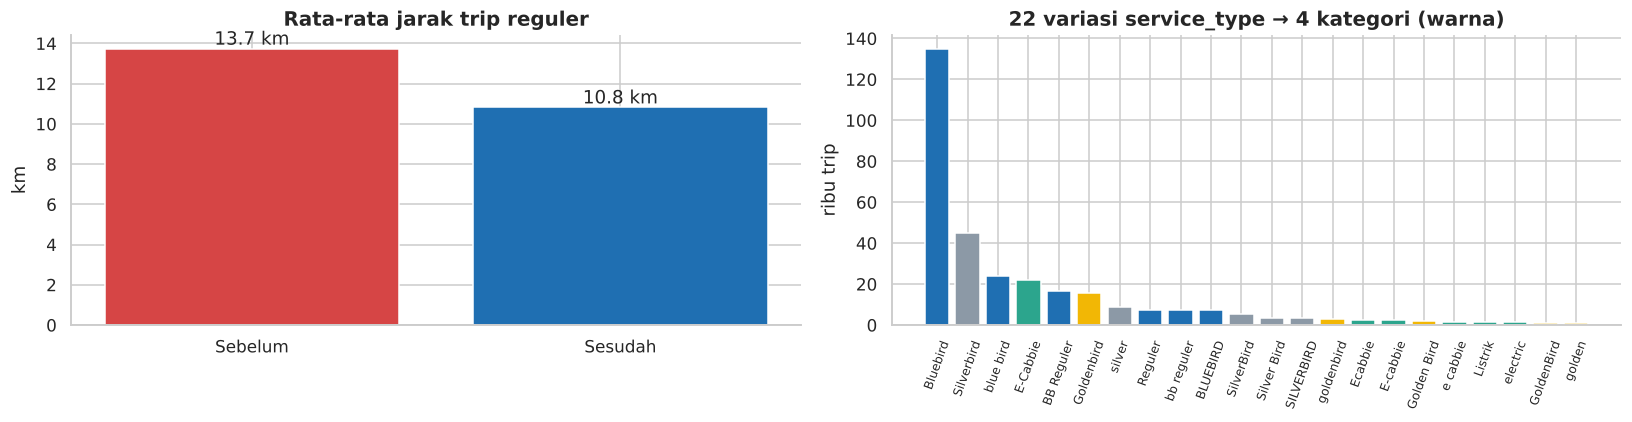

26.993765872303975


In [40]:
fig, ax = plt.subplots(1,2, figsize=(15,4))
ax[0].bar(['Sebelum','Sesudah'], [reg_t.distance_km.mean(), reg_t.distance_km_clean.mean()], color=[RED,BLUE])
for i,v in enumerate([reg_t.distance_km.mean(), reg_t.distance_km_clean.mean()]): ax[0].text(i,v+.2,f'{v:.1f} km',ha='center')
ax[0].set_title('Rata-rata jarak trip reguler'); ax[0].set_ylabel('km')
raw = trips.service_type_raw.value_counts()
ax[1].bar(range(len(raw)), raw.values/1e3, color=[{'Bluebird':BLUE,'Silverbird':GREY,'Goldenbird':AMBER,'E-Cabbie':'#2CA58D'}[svc_map[k.strip().lower()]] for k in raw.index])
ax[1].set_xticks(range(len(raw))); ax[1].set_xticklabels(raw.index, rotation=70, fontsize=8); ax[1].set_title('22 variasi service_type → 4 kategori (warna)'); ax[1].set_ylabel('ribu trip')
plt.tight_layout(); plt.show()
err_share = trips.flag_distance_error | trips.flag_time_error
RES.update(dist_mean_raw=reg_t.distance_km.mean(), dist_mean_clean=reg_t.distance_km_clean.mean(),
           dist_bias_pct=(reg_t.distance_km.mean()/reg_t.distance_km_clean.mean()-1)*100,
           n_dist_err=int(trips.flag_distance_error.sum()), n_time_err=int(trips.flag_time_error.sum()), n_outside=int(trips.flag_outside_shift.sum()),
           n_neg=int((reg & (trips.distance_km<0)).sum()), n_big=int((reg & (trips.distance_km>200)).sum()), n_charter=int((trips.trip_type=='Charter').sum()),
           err_rows_pct=err_share.mean()*100, svc_raw=int(trips.service_type_raw.nunique()))
print(RES['dist_bias_pct'])

**Insight BQ6:**
- Hanya **1,021 trip (0,3%)** yang jaraknya error, namun karena nilainya ekstrem (hingga 3.000 km), rata-rata jarak trip reguler **membengkak 27%** (13.7 → 10.8 km). KPI seperti km/hari, biaya BBM/km, atau tarif/km akan menyesatkan jika dihitung dari data mentah.
- Jika outlier dibuang secara global (IQR), **3,544 trip Charter yang sah ikut terbuang** — padahal bernilai tinggi. Penanganan harus memakai konteks bisnis (jenis trip + konsistensi tarif).
- 22 variasi penulisan layanan membuat laporan per kategori **terpecah** (mis. "Bluebird" terbagi ke 6 label).
- **Rekomendasi data:** validasi otomatis di sumber — tolak jarak ≤ 0 atau > 2× jarak implisit tarif, sinkronisasi jam (NTP) antara aplikasi & dispatch lama, dan *dropdown* master data `service_type`.

## <span style="color:#0B4F8A">5.4 B2B eVoucher</span>

### <span style="color:#0B4F8A">BQ7 — Apakah pola waktu & lokasi eVoucher berbeda? Di mana anomalinya?</span>

Logika: eVoucher adalah fasilitas **perjalanan dinas**. Pola wajar → dipakai pada **hari kerja & jam kerja**, sehingga porsinya **turun** saat akhir pekan dan larut malam. Kita bandingkan porsi eVoucher (dari seluruh trip) menurut hari & jam, di Bandara vs non-Bandara.

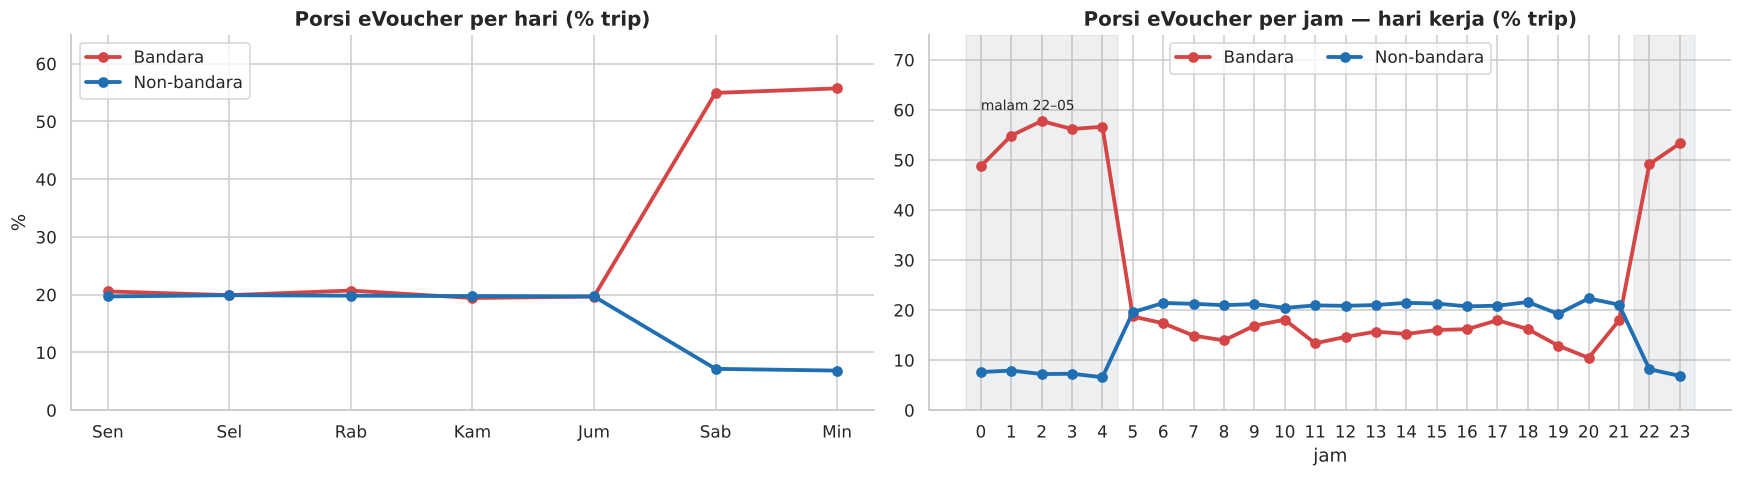

In [41]:
fig, ax = plt.subplots(1,2, figsize=(16,4.5))
tr['lokasi'] = np.where(tr.pickup_zone_type=='Airport','Bandara','Non-bandara')
dw = tr.groupby(['dow','lokasi']).is_evoucher.mean().unstack()*100
dw.index = ['Sen','Sel','Rab','Kam','Jum','Sab','Min']
dw.plot(marker='o', ax=ax[0], color=[RED,BLUE], lw=2.5); ax[0].legend(title=None); ax[0].set_title('Porsi eVoucher per hari (% trip)'); ax[0].set_ylabel('%'); ax[0].set_ylim(0,65)
hw = tr[~tr.is_weekend].groupby(['hour','lokasi']).is_evoucher.mean().unstack()*100
hw.plot(marker='o', ax=ax[1], color=[RED,BLUE], lw=2.5); ax[1].set_title('Porsi eVoucher per jam — hari kerja (% trip)'); ax[1].set_xticks(range(24)); ax[1].set_ylim(0,75); ax[1].legend(loc='upper center', ncol=2, title=None); ax[1].set_xlabel('jam')
ax[1].axvspan(-.5,4.5,color=GREY,alpha=.15); ax[1].axvspan(21.5,23.5,color=GREY,alpha=.15); ax[1].text(0,60,'malam 22–05',fontsize=9)
plt.tight_layout(); plt.show()

In [42]:
tr['window'] = np.select([tr.is_weekend, tr.is_night], ['Akhir pekan','Malam hari kerja (22–05)'], 'Hari kerja siang')
cmp = tr.groupby(['lokasi','window']).agg(trip=('trip_id','size'), evoucher=('is_evoucher','sum'), porsi=('is_evoucher','mean')).round(3)
cmp['porsi'] *= 100
display(cmp)
air = tr[tr.lokasi=='Bandara']
ct_ = pd.crosstab(air.window!='Hari kerja siang', air.is_evoucher)
chi = stats.chi2_contingency(ct_); print(f'Chi-square (Bandara) eVoucher ~ waktu tidak lazim: χ²={chi[0]:,.0f}, p={chi[1]:.2e}')
RES['chi_ev']=chi[0]; RES['chi_ev_p']=chi[1]

trip  evoucher  porsi
lokasi      window                                           
Bandara     Akhir pekan                11690      6470  55.30
            Hari kerja siang           27193      4293  15.80
            Malam hari kerja (22–05)    3292      1826  55.50
Non-bandara Akhir pekan                76927      5394   7.00
            Hari kerja siang          180860     38054  21.00
            Malam hari kerja (22–05)   18136      1321   7.30

Chi-square (Bandara) eVoucher ~ waktu tidak lazim: χ²=7,227, p=0.00e+00


In [43]:
# Estimasi trip eVoucher "berlebih": jumlah aktual di Bandara pada waktu tidak lazim dikurangi ekspektasi jika porsinya sama dengan Bandara hari kerja siang
base = air[air.window=='Hari kerja siang'].is_evoucher.mean()
unus = air[air.window!='Hari kerja siang']
excess = unus.is_evoucher.sum() - base*len(unus)
ev_unus = unus[unus.is_evoucher]
excess_fare = excess * ev_unus.total_fare.mean()
nonair = tr[tr.lokasi=='Non-bandara']
RES.update(ev_share_all=tr.is_evoucher.mean()*100, ev_air_usual=base*100, ev_air_unusual=unus.is_evoucher.mean()*100,
           ev_nonair_usual=nonair[nonair.window=='Hari kerja siang'].is_evoucher.mean()*100,
           ev_nonair_unusual=nonair[nonair.window!='Hari kerja siang'].is_evoucher.mean()*100,
           ev_sus_n=int(ev_unus.shape[0]), ev_sus_share=ev_unus.shape[0]/tr.is_evoucher.sum()*100, ev_excess=excess,
           ev_excess_fare_m=excess_fare/1e6, ev_sus_fare_m=ev_unus.total_fare.sum()/1e6,
           ev_sus_fare_med=ev_unus.total_fare.median(), ev_norm_fare_med=tr[tr.is_evoucher & ~tr.index.isin(ev_unus.index)].total_fare.median(),
           ev_sus_dist_med=ev_unus.distance_km_clean.median(), ev_norm_dist_med=tr[tr.is_evoucher & ~tr.index.isin(ev_unus.index)].distance_km_clean.median(),
           ev_dow=dw.round(2).to_dict('index'), ev_hour=hw.round(2).reset_index().to_dict('records'), ev_total_fare_b=tr[tr.is_evoucher].total_fare.sum()/1e9)
print(f"Baseline porsi eVoucher Bandara hari kerja siang: {base*100:.1f}% | waktu tidak lazim: {unus.is_evoucher.mean()*100:.1f}%")
print(f"Trip eVoucher Bandara waktu tidak lazim: {ev_unus.shape[0]:,} ({RES['ev_sus_share']:.1f}% dari semua eVoucher) | berlebih ≈ {excess:,.0f} trip ≈ Rp{excess_fare/1e6:,.0f} juta")

Baseline porsi eVoucher Bandara hari kerja siang: 15.8% | waktu tidak lazim: 55.4%
Trip eVoucher Bandara waktu tidak lazim: 8,296 (14.5% dari semua eVoucher) | berlebih ≈ 5,931 trip ≈ Rp891 juta


**Insight BQ7:**
- Di zona **non-bandara**, pola eVoucher **wajar**: porsinya 21% pada hari kerja siang dan turun ke 7% saat akhir pekan/malam — sesuai karakter perjalanan dinas.
- Di **Bandara**, polanya **terbalik**: porsi eVoucher melonjak dari **16%** (hari kerja siang) menjadi **55%** pada akhir pekan & malam (χ² p < 0,001). Lonjakan terjadi tepat di jam 22–05 dan sepanjang Sabtu–Minggu.
- Sebanyak **8,296 trip eVoucher (14.5% dari total eVoucher)** terjadi di Bandara pada waktu tidak lazim, dengan tarif median Rp128,500 (≈2× trip eVoucher lain). Dibanding baseline, terdapat **≈5,931 trip "berlebih" senilai ≈Rp891 juta** dalam 3 bulan.
- Catatan kritis: sebagian perjalanan bandara malam/akhir pekan bisa sah (penerbangan dinas). Karena itu ini **indikasi yang perlu diverifikasi**, bukan bukti fraud — tetapi skalanya terlalu besar untuk dianggap kebetulan.

### <span style="color:#0B4F8A">BQ8 — Apakah anomali terkonsentrasi pada klien/industri/pengemudi tertentu?</span>

,trip,sus_rate
industry,,
Banking,10428,14.00
Consulting,10929,14.70
FMCG,12251,14.60
Media,6211,14.70
Mining,8664,14.00
Tech StartUp,8875,14.80


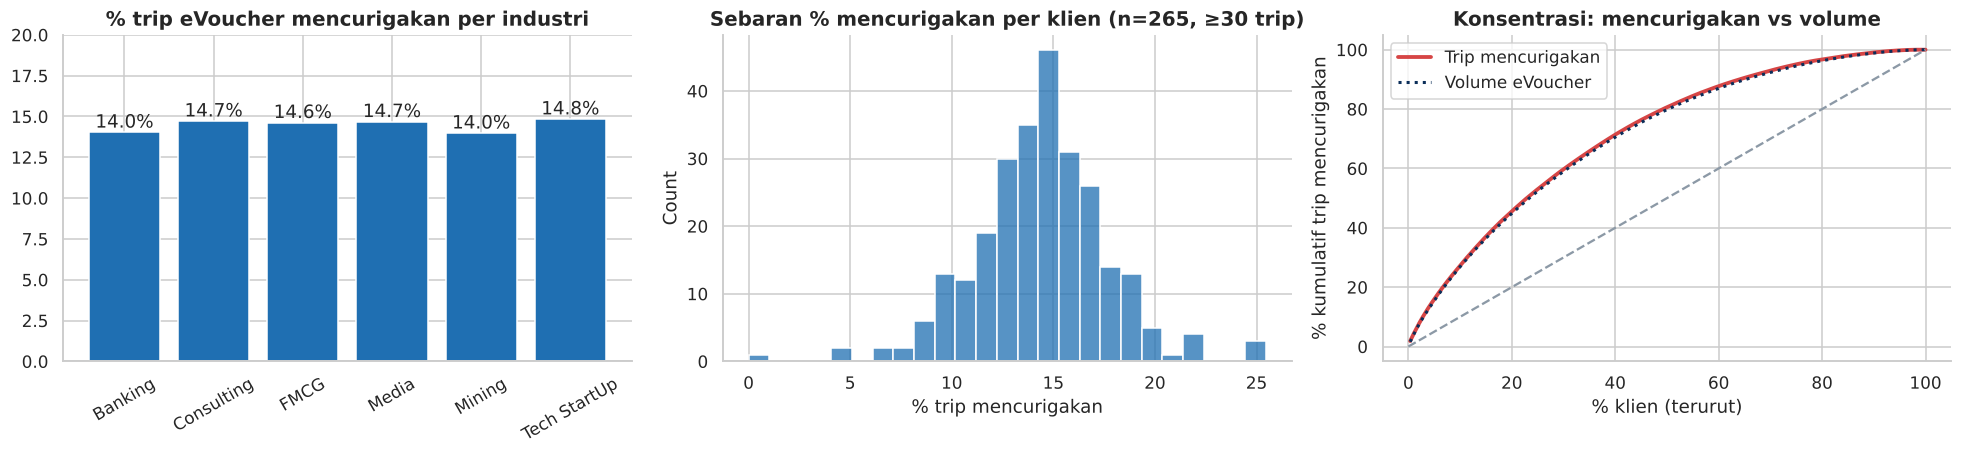

20% klien teratas menyumbang 45% trip mencurigakan — sebanding dengan porsi volume eVoucher 20% klien terbesar (45%)


In [44]:
ev = tr[tr.is_evoucher].merge(corp, on='company_id')
ev['suspicious'] = (ev.lokasi=='Bandara') & (ev.window!='Hari kerja siang')
co_ = ev.groupby(['company_id','company_name','industry']).agg(trip=('trip_id','size'), sus=('suspicious','sum'), sus_rate=('suspicious','mean'), fare=('total_fare','sum')).reset_index()
ind = ev.groupby('industry').agg(trip=('trip_id','size'), sus_rate=('suspicious','mean'))
ind['sus_rate'] *= 100
display(ind.round(1))
fig, ax = plt.subplots(1,3, figsize=(18,4.3))
ax[0].bar(ind.index, ind.sus_rate, color=BLUE); ax[0].set_title('% trip eVoucher mencurigakan per industri'); ax[0].tick_params(axis='x', rotation=30); ax[0].set_ylim(0,20)
for i,v in enumerate(ind.sus_rate): ax[0].text(i,v+.3,f'{v:.1f}%',ha='center')
big = co_[co_.trip>=30]
sns.histplot(big.sus_rate*100, bins=25, color=BLUE, ax=ax[1]); ax[1].set_title(f'Sebaran % mencurigakan per klien (n={len(big)}, ≥30 trip)'); ax[1].set_xlabel('% trip mencurigakan')
cs = co_.sort_values('sus', ascending=False); cs['cum'] = cs.sus.cumsum()/cs.sus.sum()*100
ax[2].plot(np.arange(1,len(cs)+1)/len(cs)*100, cs.cum.values, color=RED, lw=2.5, label='Trip mencurigakan')
vv = co_.sort_values('trip', ascending=False); ax[2].plot(np.arange(1,len(vv)+1)/len(vv)*100, vv.trip.cumsum().values/vv.trip.sum()*100, color=NAVY, lw=2, ls=':', label='Volume eVoucher'); ax[2].plot([0,100],[0,100],ls='--',c=GREY); ax[2].legend()
ax[2].set_title('Konsentrasi: mencurigakan vs volume'); ax[2].set_xlabel('% klien (terurut)'); ax[2].set_ylabel('% kumulatif trip mencurigakan')
plt.tight_layout(); plt.show()
top20 = cs.head(int(len(cs)*.2)).sus.sum()/cs.sus.sum()*100
vol = co_.sort_values('trip', ascending=False); top20_vol = vol.head(int(len(vol)*.2)).trip.sum()/vol.trip.sum()*100
print(f'20% klien teratas menyumbang {top20:.0f}% trip mencurigakan — sebanding dengan porsi volume eVoucher 20% klien terbesar ({top20_vol:.0f}%)')

In [45]:
pool_ev = ev.groupby('pool_name').agg(ev_trip=('trip_id','size'), sus=('suspicious','sum'))
pool_ev['share_of_sus_%'] = pool_ev.sus/pool_ev.sus.sum()*100
display(pool_ev.sort_values('sus', ascending=False).round(1))
drv = ev.groupby('driver_id').suspicious.sum()
print('Trip mencurigakan per pengemudi:', drv.describe().round(2).to_dict())
ch = ev.groupby('suspicious').booking_channel.value_counts(normalize=True).unstack()*100
display(ch.round(1))
RES.update(ev_companies=int(co_[co_.sus>0].shape[0]), ev_top20=top20, ev_top20_vol=top20_vol, ev_sus_rate_p10=big.sus_rate.quantile(.1)*100, ev_sus_rate_p90=big.sus_rate.quantile(.9)*100, ev_ind=ind.sus_rate.round(2).to_dict(),
           ev_ind_min=ind.sus_rate.min(), ev_ind_max=ind.sus_rate.max(), ev_drv_max=int(drv.max()),
           ev_cgk_share=pool_ev.loc['Pool Bandara Soetta','share_of_sus_%'], ev_street_sus=ch.loc[True,'Street Hail'], ev_street_norm=ch.loc[False,'Street Hail'],
           ev_top_clients=cs.head(5)[['company_name','industry','trip','sus']].to_dict('records'))

,ev_trip,sus,share_of_sus_%
pool_name,,,
Pool Bandara Soetta,8158,2943,35.50
Pool Ciputat,7246,971,11.70
Pool BSD,6760,883,10.60
Pool Puri,6229,813,9.80
Pool Halim,5978,788,9.50
Pool Kramat Jati,8321,690,8.30
Pool Kelapa Gading,7712,614,7.40
Pool Mampang,6954,594,7.20


Trip mencurigakan per pengemudi: {'count': 4055.0, 'mean': 2.05, 'std': 1.92, 'min': 0.0, '25%': 1.0, '50%': 2.0, '75%': 3.0, 'max': 15.0}


booking_channel,App,Call Center,Street Hail
suspicious,,,
False,55.20,36.40,8.40
True,59.90,25.30,14.80


**Insight BQ8:**
- Anomali **tersebar merata**: porsi trip mencurigakan per industri hanya berkisar 14.0–14.8%; 281 dari 286 klien memiliki trip mencurigakan, dan 80% klien (≥30 trip) berada di rentang 10–18%. 20% klien teratas menyumbang 45% trip mencurigakan — **sebanding** dengan porsi volume eVoucher mereka (45%), jadi tidak ada klien yang menyimpang secara ekstrem. Maks per pengemudi hanya 15 trip dalam 3 bulan → **bukan kolusi segelintir pengemudi atau ulah satu klien**.
- Artinya akar masalahnya adalah **celah kebijakan/kontrol**: eVoucher bisa dipakai kapan saja tanpa validasi tujuan dinas. Trip mencurigakan juga lebih banyak via **Street Hail** (15% vs 8%) — kanal yang paling sulit diverifikasi karena tanpa pemesanan tercatat.
- 35% trip mencurigakan dilayani pengemudi Pool Soetta — wajar karena lokasinya di bandara, bukan indikasi pelanggaran pengemudi.

<a id="bi"></a>
# <span style="color:#0B4F8A">6. Business Impact</span>

Estimasi dampak finansial **sebelum vs sesudah** rekomendasi diterapkan (disetahunkan = ×365/90). Asumsi dibuat konservatif dan dapat disesuaikan manajemen.

In [46]:
avg_fare_reg = trips[trips.trip_type=='Reguler'].total_fare.mean()
# 1) Pemulihan demand hilang: asumsi 50% permintaan gagal CBD jam sibuk & 25% sisanya dapat dipulihkan dengan penjadwalan ulang shift + repositioning
rec_cbd = RES['lost_cbdpk_year_b']*0.50
rec_other = (RES['lost_year_b']-RES['lost_cbdpk_year_b'])*0.25
# 2) Peningkatan ritase Pool Soetta: separuh gap menuju rata-rata pool Mixed, dengan memindahkan sebagian shift dari zona Bandara ke CBD/Mall
cgk_shifts_year = (sh.pool_name=='Pool Bandara Soetta').sum()*ANNUAL
uplift_trips = cgk_shifts_year * (RES['mixed_rit']-RES['cgk_rit'])*0.5
rit_gain = uplift_trips*avg_fare_reg/1e9
# 3) eVoucher: 70% trip berlebih dapat dicegah/ditagihkan ulang lewat approval & laporan transparansi
ev_saved = RES['ev_excess_fare_m']/1e3*ANNUAL*0.70
impact = pd.DataFrame([
 ['Pemulihan demand CBD jam sibuk','50% dari Rp{:.2f} M/thn'.format(RES['lost_cbdpk_year_b']), rec_cbd],
 ['Pemulihan demand lainnya','25% dari Rp{:.2f} M/thn'.format(RES['lost_year_b']-RES['lost_cbdpk_year_b']), rec_other],
 ['Peningkatan ritase Pool Soetta','+{:.2f} trip/shift × {:,.0f} shift/thn × Rp{:,.0f}'.format((RES['mixed_rit']-RES['cgk_rit'])*0.5, cgk_shifts_year, avg_fare_reg), rit_gain],
 ['Pengendalian eVoucher (value protected)','70% dari Rp{:.2f} M/thn trip berlebih'.format(RES['ev_excess_fare_m']/1e3*ANNUAL), ev_saved]],
 columns=['Inisiatif','Asumsi','Dampak (Rp miliar/tahun)'])
impact.loc[len(impact)] = ['TOTAL','', impact['Dampak (Rp miliar/tahun)'].sum()]
RES.update(imp_rec_cbd=rec_cbd, imp_rec_other=rec_other, imp_rit=rit_gain, imp_ev=ev_saved, impact_total_b=impact['Dampak (Rp miliar/tahun)'].iloc[-1],
           uplift_trips=uplift_trips, avg_fare_reg=avg_fare_reg, cgk_shifts_year=cgk_shifts_year, ev_excess_year_b=RES['ev_excess_fare_m']/1e3*ANNUAL)
impact.round(2)

,Inisiatif,Asumsi,Dampak (Rp miliar/tahun)
0,Pemulihan demand CBD jam sibuk,50% dari Rp1.73 M/thn,0.87
1,Pemulihan demand lainnya,25% dari Rp3.19 M/thn,0.80
2,Peningkatan ritase Pool Soetta,"+0.14 trip/shift × 162,599 shift/thn × Rp71,544",1.63
3,Pengendalian eVoucher (value protected),70% dari Rp3.61 M/thn trip berlebih,2.53
4,TOTAL,,5.83


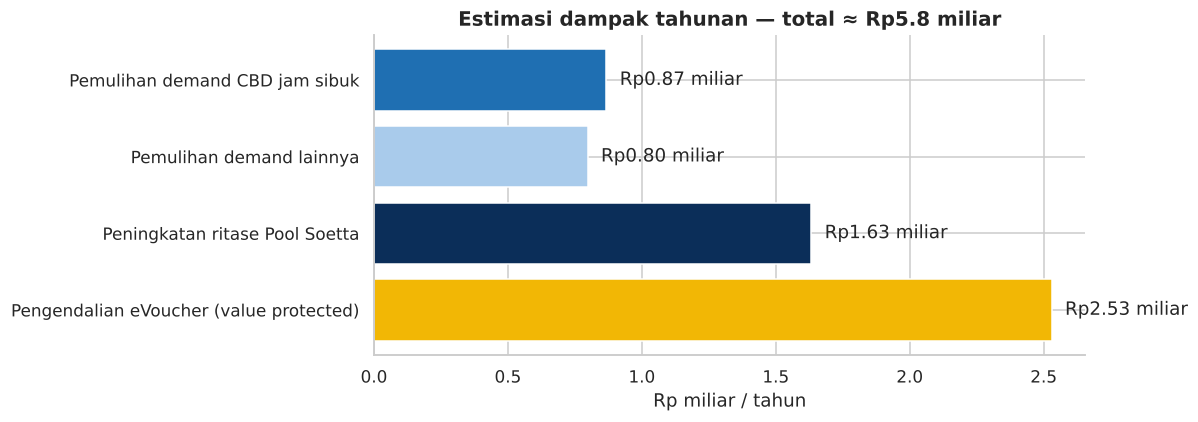

In [47]:
fig, ax = plt.subplots(figsize=(11,4))
im = impact.iloc[:-1]
ax.barh(im.Inisiatif, im['Dampak (Rp miliar/tahun)'], color=[BLUE,SKY,NAVY,AMBER]); ax.invert_yaxis()
for i,v in enumerate(im['Dampak (Rp miliar/tahun)']): ax.text(v+.05,i,f'Rp{v:.2f} miliar',va='center')
ax.set_title(f"Estimasi dampak tahunan — total ≈ Rp{RES['impact_total_b']:.1f} miliar"); ax.set_xlabel('Rp miliar / tahun')
plt.tight_layout(); plt.show()

<a id="cr"></a>
# <span style="color:#0B4F8A">7. Kesimpulan & Rekomendasi</span>

## <span style="color:#0B4F8A">7.1 Kesimpulan</span>
| Business Question | Jawaban |
|---|---|
| **BQ1** Variasi ritase antar pool | Signifikan (p<0,001), membentuk 3 klaster: CBD-heavy 1.39 > Mixed 1.25 > Soetta 0.97. Pool terbesar (Soetta) paling tidak produktif (40% shift tanpa trip). |
| **BQ2** Faktor penjelas | **Zona kerja**, bukan pengemudi. CBD 1.70 vs Bandara 0.67 trip/shift; rating, masa kerja, status & tipe armada tidak berpengaruh. |
| **BQ3** Supply vs demand per jam | Tidak sinkron: armada menumpuk 09–11, demand puncak 13–16, dan ada jeda pergantian shift 16–18 (±169 unit aktif pada 17.00). |
| **BQ4** Permintaan gagal | Terkonsentrasi di **CBD jam 07–08 & 17–18** (fulfillment 63% vs 96%), menyumbang 39% kegagalan; penyebab utama No Driver. |
| **BQ5** Pendapatan hilang | ≈Rp4.9 miliar/tahun (Rp1.7 M dari CBD jam sibuk). |
| **BQ6** Kualitas data | 0,3% trip error jarak membuat rata-rata jarak bias +27%; 22 label layanan; 2% timestamp tidak sinkron. Ditangani dengan imputasi berbasis tarif (R²≈0,97) & standardisasi. |
| **BQ7** Pola eVoucher | Wajar di non-bandara, **anomali di Bandara** saat akhir pekan/malam (55% vs 16%); ≈5,931 trip berlebih ≈Rp891 juta / 3 bulan. |
| **BQ8** Konsentrasi eVoucher | Tersebar merata di 281 klien & semua industri → **celah kebijakan**, bukan oknum. |


## <span style="color:#0B4F8A">7.2 Rekomendasi (Action Plan)</span>
**A. Untuk Direktur Operasional & Kepala Pool — Fleet Optimization**
1. **Geser jadwal shift mengikuti kurva demand.** Tambah gelombang shift *siang* (mulai 10.00–12.00) dan majukan shift malam ke 16.00–17.00 untuk menutup jeda 16–18; kurangi shift yang mulai 21–22 (demand malam < 25/jam). *KPI: armada aktif pukul 17.00 ≥ 600 unit; fulfillment jam 17–18 ≥ 90%.*
2. **Re-alokasi Pool Soetta.** Batasi antrean bandara sesuai demand (Bandara hanya 13% permintaan tapi menyerap 22% shift); arahkan 20–30% shift Pool Soetta ke CBD/Mall pada jam sibuk. *KPI: ritase Soetta ≥ 1.25 (setara pool Mixed), shift tanpa trip < 30%.*
3. **Dispatch pre-positioning CBD.** Pukul 06.30 & 16.30, dispatch mengarahkan unit idle terdekat ke titik CBD; berikan insentif ritase jam sibuk CBD. *KPI: fulfillment CBD jam sibuk dari 63% → ≥85%.*
4. **Ubah fokus KPI pool** dari jumlah unit beroperasi menjadi **ritase & utilisasi per shift**, dengan dashboard harian per pool × zona × jam.

**B. Untuk Tim Corporate Solution & Finance — B2B Fraud Mitigation**
5. **Approval berbasis aturan (rule-based):** eVoucher di luar hari kerja 05–22 atau ke/dari bandara di akhir pekan/malam memerlukan **kode perjalanan dinas/persetujuan atasan** di aplikasi klien.
6. **Batasi eVoucher Street Hail** (wajib scan QR/OTP karyawan) karena kanal ini paling sulit diverifikasi.
7. **Laporan transparansi bulanan ke klien** yang menandai trip di luar jam kerja → klien bisa mengaudit sendiri; jadikan nilai jual *Corporate Solution*. *KPI: porsi eVoucher bandara akhir pekan/malam turun dari 55% mendekati baseline ±16–25%.*

**C. Untuk Tim Data Engineering**
8. Validasi argometer di sumber (tolak jarak ≤0 / tidak konsisten dengan tarif), sinkronisasi jam (NTP) aplikasi–dispatch lama, dan master data `service_type` (dropdown).

**Prioritas:** (1) & (3) cepat dan murah — *quick win* 1 bulan; (2) & (5) butuh koordinasi dengan pool dan klien — 1 kuartal; (8) proyek data jangka menengah.


## <span style="color:#0B4F8A">7.3 Keterbatasan Analisis</span>
- Data hanya 3 bulan (Okt–Des 2023) → belum menangkap musim lain (Lebaran, libur sekolah).
- Lokasi hanya berupa kategori zona (tanpa koordinat) → rekomendasi repositioning masih di level zona.
- Tidak ada data tujuan & tujuan dinas eVoucher → anomali merupakan **indikasi** yang perlu diverifikasi bersama klien.
- Estimasi dampak bisnis memakai asumsi tingkat pemulihan (25–70%) yang perlu divalidasi melalui uji coba (pilot).


In [48]:
def conv(o):
    if isinstance(o,(np.integer,)): return int(o)
    if isinstance(o,(np.floating,)): return float(o)
    if isinstance(o,(np.bool_,)): return bool(o)
    return str(o)
json.dump(RES, open('results.json','w'), default=conv, indent=1)
print('Selesai — angka kunci tersimpan di results.json')

Selesai — angka kunci tersimpan di results.json
